# EXP-RESNET50-YOLO-PIPELINE-033 — ResNet50 + YOLO26s

Run top to bottom in a fresh Colab GPU runtime. Part A uses the frozen EXP-RESNET50-REGULARIZED-5SEEDS-032 probabilities. Part B trains five ResNet50 ImageNet transfer seeds and exports the deployable pipeline. YOLO detector, datasets, leakage audit, box calibration, fusion rules and statistics follow DenseNet121 + YOLO 032.

**Protocol disclosure.** The user's choice of ResNet50 032 instead of 031 was made for more stable Stage 2 behavior; it is not the locked `val_loss` winner (031 has lower `val_loss`), and the choice was made after Test/Holdout inspection. Holdout 09 has four classes and 126 images and is a descriptive audit, not a blind benchmark. F2 is post hoc. No Holdout value selects a model, threshold, or default rule. The clean YOLO Test split evaluates localization. Real exports require the pinned archives and a Colab GPU.

Set `EXP033_DRY_RUN=1` only for a synthetic logic check. Its scores are never reportable. ResNet50 031 sensitivity is optional and exploratory.


In [10]:
# EXP-033 configuration and imports
import base64, csv, gc, hashlib, io, json, os, platform, shutil, stat, subprocess, sys, time, zipfile
from collections import Counter, defaultdict
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image, ImageDraw, ImageOps
from scipy.stats import norm
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, log_loss, precision_recall_fscore_support)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
import joblib
import importlib.util

EXPERIMENT_ID = "EXP-RESNET50-YOLO-PIPELINE-033"
SEEDS = [42, 123, 2026, 3407, 7777]
CLASSES = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
DETECTOR_CLASSES = ["anthracnose", "leaf_miner", "red_rust"]
CLASS_NAMES = CLASSES
CLASS_INDEX = {name: i for i, name in enumerate(CLASSES)}
BASELINE_EXPERIMENT_ID = "EXP-RESNET50-REGULARIZED-5SEEDS-032-B3-LR5e6-256px-5411b7ad"
BASELINE_ANALYSIS_SHA256 = "0d3d339438726cf03867b5f02ea781dc64946919238ed28a1e8307883be6d6bd"
BASELINE_ANALYSIS_DRIVE_FILE_ID = "1iIndbkgA8V2ZkpGAOF693Sa3nt-7SHRM"
RUN_PART_A_031_SENSITIVITY = False
SENSITIVITY_031_ANALYSIS_OVERRIDE = None  # Set to a local ANALYSIS.zip when enabled.
SENSITIVITY_031_ANALYSIS_SHA256 = "85151ff0dbb9aedce08ca8d1b13c136c23ceb6e23a8af81d1d50064e24f35167"
DENSENET032_ANALYSIS_OVERRIDE = None  # Optional reference ZIP for comparison.
CLASSIFIER_SELECTION_NOTE = "User chose 032 for Stage 2 stability after Test/Holdout inspection; 031 has lower val_loss. This is not a locked val_loss selection."
DATASET_ARCHIVE_NAME = "CashewData_Split (13).zip"
DATASET_ARCHIVE_FILE_ID = "1HUE5ObO1vW0mP2QjgsdObMuW4RVPzNk7"
DATASET_ARCHIVE_EXPECTED_BYTES = 1470301553
DATASET_ARCHIVE_SHA256 = "e1647b72e10af04275dc760545f4ef17c9f44343ae119495b89ba1e3cd954e04"
REAL_HOLDOUT_ARCHIVE_NAME = "RL_Cashew_holdout (9).zip"
REAL_HOLDOUT_ARCHIVE_FILE_ID = "1QW2JYx8K6zkTs9y34f39OTBlxUOjWosZ"
REAL_HOLDOUT_EXPECTED_BYTES = 370947341
YOLO_DATASET_ARCHIVE_NAME = "CASHEW_YOLO_MASTER_FINAL_NEG_V03 (2).zip"
YOLO_DATASET_FILE_ID = "1cRQ-kR1lsEvyqvs0Qn8rhUS4mvdi4nD2"
YOLO_DATASET_EXPECTED_BYTES = 246419660
YOLO_DATASET_FINGERPRINT = "1acc0edcf7f736f9754e4977b61133a7ec5582b44d8cf3eef27208f49a202add"
DRIVE_TARGET_FOLDER_ID = "1DGKTnzsvVc60RIEn5lQgflR3s-loM24G"
DETECTOR_NAME = "EXP-Y26S-NEG-V03-001-CLASS-WEIGHTED"
DETECTOR_FULL_ZIP = "EXP-Y26S-NEG-V03-001_FULL.zip"
DETECTOR_FULL_ZIP_URL = "https://raw.githubusercontent.com/klongnguyen/KLTN_Cashew_Leaf_Disease_Classification/ac1efe16319052b6f08a3c41b4ec361bbbb19e2f/training_results/negative_evaluation/EXP-Y26S-NEG-V03-001_FULL.zip"
DETECTOR_FULL_ZIP_EXPECTED_BYTES = 51515079
DETECTOR_FULL_ZIP_SHA256 = "e1d3cc42afd356aaf3431486cb6f518344582e836872a36bfb651195deaf542d"
DETECTOR_WEIGHTS_MEMBER = "train/weights/best.pt"
DETECTOR_WEIGHTS_SHA256 = "66717b5523ba394443495378a326da26f0d24e98a331f98480f79d9d6fa18166"
DATASET_ARCHIVE_OVERRIDE = None
REAL_HOLDOUT_ARCHIVE_OVERRIDE = None
YOLO_DATASET_OVERRIDE = None
DETECTOR_WEIGHTS_OVERRIDE = None
RUN_PART_A, RUN_PART_B = True, True
UPLOAD_RESULT_ZIPS_TO_DRIVE = True
RESTORE_EXISTING_SEEDS_FROM_DRIVE = True  # Reuse the archived run for this experiment ID.
USE_EXTRA_BLIND_SET = False
EXTRA_BLIND_DRIVE_FOLDER_ID = ""  # Required only when USE_EXTRA_BLIND_SET is True.
DRY_RUN = os.environ.get("EXP033_DRY_RUN") == "1"  # Synthetic fixture only; never an EXP-033 result.
if USE_EXTRA_BLIND_SET:
    assert EXTRA_BLIND_DRIVE_FOLDER_ID.strip()
if DRY_RUN:
    RUN_PART_A, RUN_PART_B, UPLOAD_RESULT_ZIPS_TO_DRIVE = True, True, False
else:
    for package,module in (("google-api-python-client","googleapiclient"),
                           ("google-auth","google.auth")):
        try: found=importlib.util.find_spec(module)
        except ModuleNotFoundError: found=None
        if found is None: subprocess.check_call([sys.executable,"-m","pip","install",package])
PROJECT_ROOT = Path("/content") if Path("/content").is_dir() else Path.cwd()
OUT_DIR = PROJECT_ROOT / "training_results" / "current_dataset" / (EXPERIMENT_ID + ("-DRYRUN" if DRY_RUN else ""))
AGGREGATE = OUT_DIR / "aggregate"
AGGREGATE.mkdir(parents=True, exist_ok=True)
STAGE_ROOT = PROJECT_ROOT / "exp033_inputs"
YOLO_INFERENCE_CONF, YOLO_INFERENCE_IOU, YOLO_IMGSZ = 0.05, 0.7, 640
TAU = None  # Selected on clean Validation using EXP-031 procedure.
IMG_SIZE, BATCH_SIZE = 256, 16
STAGE1_LR, STAGE1_EPOCHS = 3e-4, 12
STAGE2_LR, STAGE2_EPOCHS = 5e-6, 30
STAGE2_UNFREEZE_PREFIX = "conv5_block3"
EXPECTED_BACKBONE_PARAMS = 23_587_712
EXPECTED_STAGE2_TRAINABLE_PARAMS = 4_459_520
EXPECTED_BACKBONE_BATCHNORM_LAYERS = 53
WEIGHT_DECAY, HEAD_DROPOUT = 1e-4, 0.40
REAL_OVERSAMPLE_FACTOR, SELECTION_PRIMARY_METRIC = 1, "val_loss"
assert SELECTION_PRIMARY_METRIC == "val_loss"
if DRY_RUN:
    SEEDS, STAGE1_EPOCHS, STAGE2_EPOCHS = [42, 123], 1, 1

def file_md5(path):
    digest = hashlib.md5()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(8 << 20), b""):
            digest.update(block)
    return digest.hexdigest()

def write_json(path, value):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    Path(path).write_text(json.dumps(value, indent=2, sort_keys=True, default=str), encoding="utf-8")

def unique_keys(frame, label):
    if frame["evidence_key"].duplicated().any():
        raise ValueError(f"{label}: duplicate split/class/filename keys")
    if any(len(str(key).split("/")) != 3 for key in frame["evidence_key"]):
        raise ValueError(f"{label}: keys must be split/class/filename")

def checked_join(left, right, label):
    unique_keys(left, label + " left")
    unique_keys(right, label + " right")
    a, b = set(left.evidence_key), set(right.evidence_key)
    if a != b:
        raise ValueError(f"{label}: key mismatch; missing={sorted(a-b)[:3]} extra={sorted(b-a)[:3]}")
    return left.merge(right, on="evidence_key", validate="one_to_one")

print("EXP-033", platform.python_version(), "dry_run", DRY_RUN,
      "Part A", RUN_PART_A, "Part B", RUN_PART_B)
print("Detector Val mAP50=0.7163 mAP50-95=0.3981; YOLO train/val/test=3497/951/412 (negatives 621/58/0).")
print("Detector config FINAL_TEST_EVALUATION=false; YOLO Test is the clean localization split.")


EXP-033 3.13.16 dry_run False Part A True Part B True
Detector Val mAP50=0.7163 mAP50-95=0.3981; YOLO train/val/test=3497/951/412 (negatives 621/58/0).
Detector config FINAL_TEST_EVALUATION=false; YOLO Test is the clean localization split.


In [11]:
# 01a. Pinned 15-file ResNet50 032 prediction bundle.
# The source ANALYSIS ZIP SHA256 was checked at notebook build time: 0d3d339438726cf03867b5f02ea781dc64946919238ed28a1e8307883be6d6bd.
# Every embedded CSV has a SHA256 in manifest.json and is rechecked at runtime.
RES032_PREDICTION_BUNDLE_SHA256 = "003521bbf731c2ba85430ba660d87fd97445d4c450242ba6b48092a314995c1c"
RES032_PREDICTION_BUNDLE_B64 = "..."


In [12]:
# Stage pinned inputs. Source helpers copied from EXP-031 by header.
def archive_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(8 << 20), b''):
            digest.update(block)
    return digest.hexdigest()

def source_archive(file_id, name, expected_bytes, override):
    if override:
        path = Path(override).expanduser()
        if not path.is_file():
            raise FileNotFoundError(f'Archive override missing: {path}')
    else:
        path = STAGE_ROOT / 'archives' / name
        path.parent.mkdir(parents=True, exist_ok=True)
        if not path.is_file() or path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
            if not file_id:
                raise FileNotFoundError(f'{name}: set a Drive file ID or archive override')
            import google.auth
            from googleapiclient.discovery import build
            from googleapiclient.http import MediaIoBaseDownload
            if Path('/content').is_dir():
                from google.colab import auth
                auth.authenticate_user()
            credentials, _ = google.auth.default(scopes=['https://www.googleapis.com/auth/drive.readonly'])
            service = build('drive', 'v3', credentials=credentials, cache_discovery=False)
            meta = service.files().get(fileId=file_id, fields='id,name,size,md5Checksum',
                                       supportsAllDrives=True).execute()
            if meta['name'] != name or int(meta['size']) != expected_bytes:
                raise ValueError(f'Drive source differs from expected {name}: {meta}')
            partial = path.with_suffix(path.suffix + '.part')
            request = service.files().get_media(fileId=file_id, supportsAllDrives=True)
            with partial.open('wb') as stream:
                downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                done = False
                while not done:
                    progress, done = downloader.next_chunk(num_retries=3)
                    if progress:
                        print(name, f'{progress.progress():.0%}')
            if partial.stat().st_size != expected_bytes or not zipfile.is_zipfile(partial):
                raise RuntimeError(f'Incomplete archive download: {name}')
            if meta.get('md5Checksum'):
                digest = hashlib.md5()
                with partial.open('rb') as stream:
                    for block in iter(lambda: stream.read(8 << 20), b''):
                        digest.update(block)
                if digest.hexdigest() != meta['md5Checksum']:
                    raise RuntimeError(f'Drive MD5 mismatch: {name}')
            partial.replace(path)
    if path.stat().st_size != expected_bytes or not zipfile.is_zipfile(path):
        raise ValueError(f'Archive size/type mismatch: {path}')
    return path

def extract_verified(archive_path, destination):
    archive_path, destination = Path(archive_path), Path(destination)
    checksum = archive_sha256(archive_path)
    marker = destination / '.archive_sha256'
    if destination.is_dir():
        if not marker.is_file() or marker.read_text(encoding='utf-8').strip() != checksum:
            raise RuntimeError(f'Unverified/incomplete extraction: {destination}')
        return destination
    staging = destination.with_name(destination.name + '_staging')
    if staging.exists():
        raise RuntimeError(f'Incomplete staging directory: {staging}')
    staging.mkdir(parents=True)
    with zipfile.ZipFile(archive_path) as archive:
        resolved_root = staging.resolve()
        for member in archive.infolist():
            target = (staging / member.filename.replace('\\', '/')).resolve()
            if (stat.S_ISLNK(member.external_attr >> 16) or
                    not target.is_relative_to(resolved_root)):
                raise ValueError(f'Unsafe archive member: {member.filename}')
        archive.extractall(staging)
    (staging / '.archive_sha256').write_text(checksum + '\n', encoding='utf-8')
    staging.rename(destination)
    return destination


def ensure_detector_weights(project_root, override, archive_name, archive_url,
                            archive_bytes, archive_sha256, weights_member,
                            weights_sha256):
    """Return a verified best.pt, reusing local files before downloading."""
    project_root = Path(project_root)
    weights = Path(override).expanduser() if override else project_root / 'detector' / 'best.pt'
    if weights.is_file():
        found = file_sha256(weights)
        if found != weights_sha256:
            raise ValueError(f'YOLO best.pt SHA256 mismatch: {found}')
        print('Verified YOLO best.pt:', weights, found[:16])
        return weights
    if override:
        raise FileNotFoundError(f'DETECTOR_WEIGHTS_OVERRIDE does not exist: {weights}')

    candidates = sorted(project_root.rglob(archive_name))
    if len(candidates) > 1:
        raise RuntimeError(f'Multiple YOLO FULL ZIPs found; select one explicitly: {candidates}')
    if candidates:
        archive_path = candidates[0]
        source = 'local archive'
    else:
        import urllib.request
        archive_path = project_root / 'detector' / archive_name
        archive_path.parent.mkdir(parents=True, exist_ok=True)
        partial = archive_path.with_suffix('.zip.part')
        request = urllib.request.Request(archive_url,
                                         headers={'User-Agent': 'EXP-031-checkpoint-provenance'})
        try:
            with urllib.request.urlopen(request, timeout=60) as response, partial.open('wb') as target:
                while True:
                    block = response.read(8 << 20)
                    if not block:
                        break
                    target.write(block)
            if partial.stat().st_size != archive_bytes:
                raise ValueError(f'Incomplete YOLO FULL ZIP: {partial.stat().st_size} bytes')
            actual = file_sha256(partial)
            if actual != archive_sha256:
                raise ValueError(f'YOLO FULL ZIP SHA256 mismatch: {actual}')
            partial.replace(archive_path)
        except Exception as exc:
            partial.unlink(missing_ok=True)
            raise RuntimeError(
                'Could not fetch the pinned YOLO FULL ZIP from GitHub. '
                'Place the verified ZIP on the runtime or set DETECTOR_WEIGHTS_OVERRIDE.'
            ) from exc
        source = 'pinned GitHub commit'

    if archive_path.stat().st_size != archive_bytes:
        raise ValueError(f'YOLO FULL ZIP size mismatch: {archive_path}')
    found_zip = file_sha256(archive_path)
    if found_zip != archive_sha256:
        raise ValueError(f'YOLO FULL ZIP SHA256 mismatch: {found_zip}')
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise ValueError(f'Corrupt YOLO FULL ZIP: {archive_path}')
        checkpoint = archive.read(weights_member)
    found_weights = hashlib.sha256(checkpoint).hexdigest()
    if found_weights != weights_sha256:
        raise ValueError(f'YOLO best.pt SHA256 mismatch: {found_weights}')
    weights.parent.mkdir(parents=True, exist_ok=True)
    temp_weights = weights.with_suffix('.pt.part')
    temp_weights.write_bytes(checkpoint)
    temp_weights.replace(weights)
    print('Verified YOLO best.pt from', source, '|', archive_path,
          '| SHA256', found_weights[:16])
    return weights


import urllib.request
IMAGE_SUFFIXES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def image_files(root):
    return sorted(p for p in Path(root).rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_SUFFIXES)

def dataset_root(extracted, kind):
    candidates = [Path(extracted), *[p for p in Path(extracted).rglob("*") if p.is_dir()]]
    if kind == "split13":
        matches = [p for p in candidates if (p / "train").is_dir() and (p / "val").is_dir() and (p / "test").is_dir()]
    elif kind == "holdout09":
        matches = [p for p in candidates if all((p / c).is_dir() for c in CLASSES[:4]) and
                   len([q for q in p.iterdir() if q.is_dir()]) == 4]
    elif kind == "yolo":
        matches = [p for p in candidates if all((p / "images" / s).is_dir() and (p / "labels" / s).is_dir()
                   for s in ("train", "val", "test"))]
    else:
        raise ValueError(kind)
    if len(matches) != 1:
        raise RuntimeError(f"{kind}: expected one root, found {matches}")
    return matches[0]

def synthetic_fixture():
    import tempfile
    root = STAGE_ROOT / "synthetic_exp033"
    if root.exists():
        shutil.rmtree(root)
    split_root, hold_root, yolo_root = root / "split13", root / "holdout09", root / "yolo"
    rng = np.random.default_rng(32)
    for split, classes, per_class in (("train", CLASSES, 2), ("val", CLASSES, 2),
                                      ("test", CLASSES, 2), ("holdout", CLASSES[:4], 2)):
        for ci, cls in enumerate(classes):
            for i in range(per_class):
                target = (hold_root if split == "holdout" else split_root / split) / cls / f"{cls}_{split}_{i}.png"
                target.parent.mkdir(parents=True, exist_ok=True)
                pixels = rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)
                pixels[:, :, ci % 3] = np.clip(pixels[:, :, ci % 3].astype(int) + 45, 0, 255)
                Image.fromarray(pixels.astype(np.uint8)).save(target)
    for split, count in (("train", 10), ("val", 6), ("test", 6)):
        for i in range(count):
            image = yolo_root / "images" / split / f"{'real_' if i % 2 else ''}{split}_{i}.png"
            label = yolo_root / "labels" / split / (image.stem + ".txt")
            image.parent.mkdir(parents=True, exist_ok=True)
            label.parent.mkdir(parents=True, exist_ok=True)
            Image.fromarray(rng.integers(0, 255, (48, 48, 3), dtype=np.uint8)).save(image)
            label.write_text(f"{i % 3} 0.5 0.5 0.4 0.4\n", encoding="utf-8")
    return split_root, hold_root, yolo_root

if DRY_RUN:
    SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT = synthetic_fixture()
    DETECTOR_WEIGHTS_PATH = None
    print("Synthetic fixture:", SPLIT13_ROOT, HOLDOUT_ROOT, YOLO_ROOT)
else:
    # Decode and verify only the pinned prediction bundle, then stage Validation.
    RES032_BUNDLE_BYTES = base64.b64decode(RES032_PREDICTION_BUNDLE_B64, validate=True)
    if hashlib.sha256(RES032_BUNDLE_BYTES).hexdigest() != RES032_PREDICTION_BUNDLE_SHA256:
        raise RuntimeError("ResNet50 032 embedded prediction bundle SHA256 mismatch")
    target = STAGE_ROOT / "resnet032"
    with zipfile.ZipFile(io.BytesIO(RES032_BUNDLE_BYTES)) as archive:
        if archive.testzip() is not None:
            raise RuntimeError("Corrupt ResNet50 032 embedded bundle")
        RES032_MANIFEST = json.loads(archive.read("manifest.json"))
    if RES032_MANIFEST["source_analysis_sha256"] != BASELINE_ANALYSIS_SHA256:
        raise RuntimeError("ResNet50 032 source ANALYSIS hash differs")
    ANALYSIS_ROOT = target / BASELINE_EXPERIMENT_ID

    def ensure_res032_split(split):
        if split in ("test", "holdout") and not (AGGREGATE / "frozen_config_partA.json").is_file():
            raise RuntimeError("Freeze Part A on clean Validation before reading Test/Holdout CSVs")
        expected = [
            f"{BASELINE_EXPERIMENT_ID}/real_holdout/seed_{seed}/predictions_standard.csv"
            if split == "holdout" else
            f"{BASELINE_EXPERIMENT_ID}/seed_{seed}/{split}/predictions_standard.csv"
            for seed in SEEDS
        ]
        with zipfile.ZipFile(io.BytesIO(RES032_BUNDLE_BYTES)) as archive:
            for name in expected:
                expected_sha = RES032_MANIFEST["members"][name]
                destination = target / name
                if not destination.resolve().is_relative_to(target.resolve()):
                    raise RuntimeError("Unsafe prediction bundle member")
                destination.parent.mkdir(parents=True, exist_ok=True)
                if not destination.is_file() or file_sha256(destination) != expected_sha:
                    data = archive.read(name)
                    if hashlib.sha256(data).hexdigest() != expected_sha:
                        raise RuntimeError(f"Prediction CSV SHA256 mismatch: {name}")
                    destination.write_bytes(data)
    ensure_res032_split("validation")
    split_archive = source_archive(DATASET_ARCHIVE_FILE_ID, DATASET_ARCHIVE_NAME,
                                   DATASET_ARCHIVE_EXPECTED_BYTES, DATASET_ARCHIVE_OVERRIDE)
    assert file_sha256(split_archive) == DATASET_ARCHIVE_SHA256
    hold_archive = source_archive(REAL_HOLDOUT_ARCHIVE_FILE_ID, REAL_HOLDOUT_ARCHIVE_NAME,
                                  REAL_HOLDOUT_EXPECTED_BYTES, REAL_HOLDOUT_ARCHIVE_OVERRIDE)
    yolo_archive = source_archive(YOLO_DATASET_FILE_ID, YOLO_DATASET_ARCHIVE_NAME,
                                  YOLO_DATASET_EXPECTED_BYTES, YOLO_DATASET_OVERRIDE)
    SPLIT13_ROOT = dataset_root(extract_verified(split_archive, STAGE_ROOT / "split13"), "split13")
    HOLDOUT_ROOT = dataset_root(extract_verified(hold_archive, STAGE_ROOT / "holdout09"), "holdout09")
    YOLO_ROOT = dataset_root(extract_verified(yolo_archive, STAGE_ROOT / "yolo"), "yolo")
    DETECTOR_WEIGHTS_PATH = ensure_detector_weights(
        PROJECT_ROOT, DETECTOR_WEIGHTS_OVERRIDE, DETECTOR_FULL_ZIP,
        DETECTOR_FULL_ZIP_URL, DETECTOR_FULL_ZIP_EXPECTED_BYTES,
        DETECTOR_FULL_ZIP_SHA256, DETECTOR_WEIGHTS_MEMBER, DETECTOR_WEIGHTS_SHA256)

SPLIT_DIRS = {"train": SPLIT13_ROOT / "train", "validation": SPLIT13_ROOT / "val",
              "test": SPLIT13_ROOT / "test", "holdout": HOLDOUT_ROOT}
YOLO_DIRS = {split: YOLO_ROOT / "images" / split for split in ("train", "val", "test")}
YOLO_LABEL_DIRS = {split: YOLO_ROOT / "labels" / split for split in ("train", "val", "test")}
if not DRY_RUN:
    assert [len(image_files(SPLIT_DIRS[s])) for s in ("train", "validation", "test", "holdout")] == [4972,1452,685,126]
    assert [len(image_files(YOLO_DIRS[s])) for s in ("train", "val", "test")] == [3497,951,412]

def inventory(split, root):
    rows = [{"evidence_key": f"{split}/{('_detector/' if split.startswith('yolo_') else '')}{p.relative_to(root).as_posix()}",
             "path": str(p), "true_label": p.parent.name} for p in image_files(root)]
    frame = pd.DataFrame(rows)
    unique_keys(frame, split)
    return frame

INVENTORY = {s: inventory(s, path) for s, path in SPLIT_DIRS.items()}
YOLO_INVENTORY = {s: inventory("yolo_" + s, path) for s, path in YOLO_DIRS.items()}
print("Classifier images", {s: len(f) for s,f in INVENTORY.items()})
print("YOLO images", {s: len(f) for s,f in YOLO_INVENTORY.items()})


Verified YOLO best.pt: /content/detector/best.pt 66717b5523ba3944
Classifier images {'train': 4972, 'validation': 1452, 'test': 685, 'holdout': 126}
YOLO images {'train': 3497, 'val': 951, 'test': 412}


In [13]:
# Frozen ResNet50 032 probabilities and pixel/pHash leakage audit.
PROB_COLUMNS = [f"prob_{name}" for name in CLASSES]

def load_res032_split(split):
    if DRY_RUN:
        rng = np.random.default_rng(29032)
        frames = []
        for seed in SEEDS:
            rows = []
            for row in INVENTORY[split].itertuples():
                p = rng.dirichlet(np.ones(len(CLASSES)) * .1)
                p[CLASS_INDEX[row.true_label]] += 3.0
                p /= p.sum()
                rows.append({"evidence_key": row.evidence_key, "true_label": row.true_label,
                             **dict(zip(PROB_COLUMNS, p))})
            frame = pd.DataFrame(rows)
            frame["seed"] = seed
            frames.append(frame)
    else:
        ensure_res032_split(split)
        frames = []
        for seed in SEEDS:
            path = (ANALYSIS_ROOT / "real_holdout" / f"seed_{seed}" / "predictions_standard.csv"
                    if split == "holdout" else ANALYSIS_ROOT / f"seed_{seed}" / split / "predictions_standard.csv")
            source = pd.read_csv(path)
            required = set(PROB_COLUMNS) | {"image_id", "true_label", "dataset_sha256", "seed"}
            if not required.issubset(source.columns) or len([c for c in source if c.startswith("prob_")]) != 5:
                raise ValueError(f"Unexpected ResNet50 prediction schema: {path}")
            if set(source.dataset_sha256.astype(str).str.lower()) != {DATASET_ARCHIVE_SHA256}:
                raise ValueError(f"Split 13 dataset hash mismatch: {path}")
            if set(source.seed.astype(int)) != {seed}:
                raise ValueError(f"Prediction seed mismatch: {path}")
            def normalize_key(image_id):
                parts = str(image_id).replace("\\", "/").split("/")
                expected_prefix = {"validation": "val", "test": "test",
                                   "holdout": "real_holdout"}[split]
                if len(parts) != 3 or parts[0] != expected_prefix:
                    raise ValueError(f"Unexpected image_id prefix in {path}: {image_id}")
                parts = parts[1:]
                if len(parts) != 2 or parts[0] not in CLASSES or not parts[1]:
                    raise ValueError(f"Unexpected image_id in {path}: {image_id}")
                return split + "/" + "/".join(parts)
            frame = source[["true_label"] + PROB_COLUMNS].copy()
            frame.insert(0, "evidence_key", source.image_id.map(normalize_key))
            frame["seed"] = seed
            frames.append(frame)
    expected = set(INVENTORY[split].evidence_key)
    for frame in frames:
        unique_keys(frame, f"ResNet50 032 {split}")
        assert set(frame.evidence_key) == expected
        assert (frame.evidence_key.str.split("/").str[1] == frame.true_label).all()
        assert np.isfinite(frame[PROB_COLUMNS].to_numpy(dtype=float)).all()
        assert (frame[PROB_COLUMNS].to_numpy(dtype=float) >= 0).all()
        assert np.allclose(frame[PROB_COLUMNS].sum(axis=1), 1, atol=1e-4)
    ensemble = frames[0][["evidence_key", "true_label"]].copy()
    for cls in CLASSES:
        ensemble[f"prob_{cls}"] = np.mean([f.set_index("evidence_key").loc[ensemble.evidence_key, f"prob_{cls}"].to_numpy()
                                                 for f in frames], axis=0)
    seed_dir = OUT_DIR / "partA_seed_predictions"
    seed_dir.mkdir(exist_ok=True)
    for seed, frame in zip(SEEDS, frames):
        frame.to_csv(seed_dir / f"{split}_seed_{seed}.csv", index=False)
    return ensemble

def pixel_sha256(path):
    with Image.open(path) as handle:
        rgb = ImageOps.exif_transpose(handle).convert("RGB")
        digest = hashlib.sha256(f"{rgb.width}x{rgb.height}:".encode())
        digest.update(rgb.tobytes())
        return digest.hexdigest()

def phash64(path):
    # EXP-031's FFT pHash, with the DC bit restored to form a full 64-bit word.
    with Image.open(path) as handle:
        gray = ImageOps.exif_transpose(handle).convert("L").resize((32,32), Image.BILINEAR)
    low = np.fft.fft2(np.asarray(gray, dtype=np.float32))[:8,:8].real.flatten()
    bits = low[1:] > np.median(low[1:])
    return (1 << 63) | int("".join("1" if bit else "0" for bit in bits), 2)

def fingerprint(frame):
    out = frame[["evidence_key", "path"]].copy()
    out["pixel_sha256"] = [pixel_sha256(p) for p in out.path]
    out["phash64"] = [phash64(p) for p in out.path]
    unique_keys(out, "fingerprint")
    return out

train_fp = fingerprint(YOLO_INVENTORY["train"])
target_fp = {s: fingerprint(INVENTORY[s]) for s in ("validation", "test", "holdout")}
target_fp["yolo_test"] = fingerprint(YOLO_INVENTORY["test"])
train_by_pixel = defaultdict(list)
for row in train_fp.itertuples():
    train_by_pixel[row.pixel_sha256].append(row.evidence_key)
train_hashes = [(r.evidence_key, int(r.phash64)) for r in train_fp.itertuples()]
AUDIT, NEAR_KEYS = {}, {}
for split, frame in target_fp.items():
    pairs, exact, near_keys = [], [], set()
    for row in frame.itertuples():
        matches = train_by_pixel.get(row.pixel_sha256, [])
        exact.extend({"target": row.evidence_key, "train": key} for key in matches)
        for key, value in train_hashes:
            distance = (int(row.phash64) ^ value).bit_count()
            if distance <= 4:
                pairs.append({"target": row.evidence_key, "train": key, "hamming": distance})
                near_keys.add(row.evidence_key)
    pd.DataFrame(pairs, columns=["target","train","hamming"]).to_csv(AGGREGATE / f"leak_{split}_near.csv", index=False)
    AUDIT[split] = {"exact_pairs": len(exact), "near_pairs": len(pairs),
                    "near_images": len(near_keys), "exact_keys": sorted({r["target"] for r in exact})}
    NEAR_KEYS[split] = near_keys
    print(split, AUDIT[split])
    if split in ("test", "holdout") and exact:
        raise RuntimeError(f"Exact YOLO-train leakage in {split}")
    if split == "yolo_test" and exact:
        raise RuntimeError("YOLO test contains exact YOLO-train images")
write_json(AGGREGATE / "leakage_audit.json", AUDIT)
CLEAN_VAL_KEYS = set(INVENTORY["validation"].evidence_key) - NEAR_KEYS["validation"]
assert CLEAN_VAL_KEYS
if not DRY_RUN:
    print("EXP-031 leakage reference: 91 excluded Validation images, 247 near pairs; recomputed:",
          len(NEAR_KEYS["validation"]), AUDIT["validation"]["near_pairs"])
    print("EXP-031 reference: Holdout 0 exact/0 near; Test 0 exact/62 near pairs.")

def phash_groups(frame):
    keys = frame.evidence_key.tolist()
    hashes = frame.phash64.tolist()
    parent = list(range(len(keys)))
    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i
    for i in range(len(keys)):
        for j in range(i+1, len(keys)):
            if (int(hashes[i]) ^ int(hashes[j])).bit_count() <= 4:
                parent[find(j)] = find(i)
    return {key: find(i) for i,key in enumerate(keys)}

VAL_GROUPS = phash_groups(target_fp["validation"][target_fp["validation"].evidence_key.isin(CLEAN_VAL_KEYS)])
assert len(set(VAL_GROUPS.values())) >= 5 or DRY_RUN
print("Clean Validation", len(CLEAN_VAL_KEYS), "pHash groups", len(set(VAL_GROUPS.values())))


validation {'exact_pairs': 0, 'near_pairs': 247, 'near_images': 91, 'exact_keys': []}
test {'exact_pairs': 0, 'near_pairs': 62, 'near_images': 23, 'exact_keys': []}
holdout {'exact_pairs': 0, 'near_pairs': 0, 'near_images': 0, 'exact_keys': []}
yolo_test {'exact_pairs': 0, 'near_pairs': 49, 'near_images': 16, 'exact_keys': []}
EXP-031 leakage reference: 91 excluded Validation images, 247 near pairs; recomputed: 91 247
EXP-031 reference: Holdout 0 exact/0 near; Test 0 exact/62 near pairs.
Clean Validation 1361 pHash groups 1350


In [14]:
# One detector pass per classifier split; one low-conf pass per YOLO split.
if DRY_RUN:
    detector = None  # Deterministic stub; no YOLO weights are used.
else:
    try:
        from ultralytics import YOLO
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "ultralytics"])
        from ultralytics import YOLO
    detector = YOLO(str(DETECTOR_WEIGHTS_PATH))
    actual_names = detector.names if isinstance(detector.names, dict) else dict(enumerate(detector.names))
    assert [actual_names[i] for i in sorted(actual_names)] == DETECTOR_CLASSES
    assert file_sha256(DETECTOR_WEIGHTS_PATH) == DETECTOR_WEIGHTS_SHA256

def infer_split(frame, split, conf):
    rows = []
    paths = frame.path.tolist()
    for pos,path in enumerate(paths):
        # The deployed pipeline processes one leaf photo at a time. Use the
        # same Ultralytics letterbox mode here so evidence is reproducible.
        result = None if DRY_RUN else detector.predict(str(path), conf=conf,
                    iou=YOLO_INFERENCE_IOU, imgsz=YOLO_IMGSZ,
                    rect=False, verbose=False)[0]
        key = frame.iloc[pos].evidence_key
        if DRY_RUN:
            with Image.open(path) as im:
                width,height = im.size
            label = frame.iloc[pos].true_label
            cls = (DETECTOR_CLASSES.index(label) if label in DETECTOR_CLASSES
                   else (int(Path(path).stem.split("_")[-1])%3 if split.startswith("yolo_") else 0))
            found = [(cls, .75, [width*.3,height*.3,width*.7,height*.7])]
        else:
            height,width = result.orig_shape
            found = [(int(c),float(q),xy.tolist()) for c,q,xy in zip(
                result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy(),
                result.boxes.xyxy.cpu().numpy())]
        for cls,score,xy in found:
            rows.append({"evidence_key": key, "cls": DETECTOR_CLASSES[cls], "conf": score,
                         "x1": xy[0], "y1": xy[1], "x2": xy[2], "y2": xy[3],
                         "img_w": width, "img_h": height})
    print(split, len(paths), "images", len(rows), "boxes", "conf", conf)
    return pd.DataFrame(rows, columns=["evidence_key","cls","conf","x1","y1","x2","y2","img_w","img_h"])

BOX_FRAMES = {}
for split in ("validation","test","holdout"):
    BOX_FRAMES[split] = infer_split(INVENTORY[split], split, .05)
for split in ("val",):
    BOX_FRAMES["yolo_"+split] = infer_split(YOLO_INVENTORY[split], "yolo_"+split, .001)
BOXES = pd.concat(BOX_FRAMES.values(), ignore_index=True)
BOXES.to_csv(AGGREGATE / "detector_boxes.csv", index=False)

def evidence_table(inventory, boxes, minimum=.05):
    boxmap = {k:g for k,g in boxes[boxes.conf >= minimum].groupby("evidence_key")}
    rows = []
    for key in inventory.evidence_key:
        group = boxmap.get(key)
        row = {"evidence_key": key}
        for cls in DETECTOR_CLASSES:
            part = group[group.cls == cls] if group is not None else None
            row[f"max_conf_{cls}"] = float(part.conf.max()) if part is not None and len(part) else 0.0
            row[f"n_boxes_{cls}"] = int(len(part)) if part is not None else 0
            row[f"area_frac_{cls}"] = (float(np.minimum(((part.x2-part.x1)*(part.y2-part.y1)).sum() /
                                  (part.img_w.iloc[0]*part.img_h.iloc[0]),1)) if part is not None and len(part) else 0.0)
        rows.append(row)
    out = pd.DataFrame(rows)
    unique_keys(out,"detector evidence")
    assert set(out.evidence_key) == set(inventory.evidence_key)
    return out

EVIDENCE = {s: evidence_table(INVENTORY[s], BOX_FRAMES[s]) for s in ("validation","test","holdout")}
for split, frame in EVIDENCE.items():
    frame.to_csv(AGGREGATE / f"detector_evidence_{split}.csv", index=False)

def iou(a,b):
    x1,y1,x2,y2 = max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])
    inter = max(0,x2-x1)*max(0,y2-y1)
    aa = max(0,a[2]-a[0])*max(0,a[3]-a[1]); bb = max(0,b[2]-b[0])*max(0,b[3]-b[1])
    return inter/(aa+bb-inter) if aa+bb>inter else 0.0

def display_boxes(frame, box_conf, label=None, abstain=False):
    if abstain or label in ("healthy","not_cashew_leaf"):
        return []
    subset = frame[frame.conf >= box_conf].sort_values("conf", ascending=False)
    if label:
        subset = subset[subset.cls == label]
    kept = []
    for row in subset.itertuples():
        xy = [row.x1,row.y1,row.x2,row.y2]
        if all(row.cls != old["cls"] or iou(xy,old["xyxy"]) <= .5 for old in kept):
            kept.append({"cls":row.cls,"conf":float(row.conf),"xyxy":xy})
        if len(kept) >= 20:
            break
    return kept


validation 1452 images 130999 boxes conf 0.05
test 685 images 51899 boxes conf 0.05
holdout 126 images 6581 boxes conf 0.05
yolo_val 951 images 199741 boxes conf 0.001


In [15]:
# YOLO-only localization on its untouched Test, with Val-only BOX_CONF selection.
def read_yolo_gt(split):
    rows=[]
    for image in YOLO_INVENTORY[split].itertuples():
        with Image.open(image.path) as handle:
            width,height=handle.size
        label=YOLO_LABEL_DIRS[split]/(Path(image.path).stem+".txt")
        if not label.is_file(): continue
        for line in label.read_text(encoding="utf-8").splitlines():
            parts=line.split()
            if len(parts)<5: continue
            cls,cx,cy,bw,bh=map(float,parts[:5]); cls=int(cls)
            rows.append({"evidence_key":image.evidence_key,"cls":DETECTOR_CLASSES[cls],
                         "xyxy":[(cx-bw/2)*width,(cy-bh/2)*height,
                                 (cx+bw/2)*width,(cy+bh/2)*height]})
    return pd.DataFrame(rows,columns=["evidence_key","cls","xyxy"])

GT_VAL=read_yolo_gt("val")

def match_boxes(boxes,gt,iou_threshold=.5):
    pred=boxes.sort_values("conf",ascending=False).reset_index(drop=True)
    used=set();tp=[]
    gt_by={(k,c):list(g.xyxy) for (k,c),g in gt.groupby(["evidence_key","cls"])}
    for row in pred.itertuples():
        candidates=gt_by.get((row.evidence_key,row.cls),[])
        overlaps=[iou([row.x1,row.y1,row.x2,row.y2],box) if (row.evidence_key,row.cls,j) not in used else -1
                  for j,box in enumerate(candidates)]
        best=int(np.argmax(overlaps)) if overlaps else -1
        good=best>=0 and overlaps[best]>=iou_threshold
        if good: used.add((row.evidence_key,row.cls,best))
        tp.append(int(good))
    return pred,np.asarray(tp,dtype=int)

def precision_recall_f1(boxes,gt,cls):
    pred,tp=match_boxes(boxes[boxes.cls==cls],gt[gt.cls==cls])
    n=len(pred); g=int((gt.cls==cls).sum()); t=int(tp.sum())
    precision=t/n if n else 0.0;recall=t/g if g else 0.0
    return precision,recall,2*precision*recall/(precision+recall) if precision+recall else 0.0,t,n,g

def filtered_table(boxes,threshold):
    rows=[]
    for key,group in boxes.groupby("evidence_key"):
        for box in display_boxes(group,threshold):
            x1,y1,x2,y2=box["xyxy"]
            rows.append({"evidence_key":key,"cls":box["cls"],"conf":box["conf"],
                         "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                         "img_w":group.img_w.iloc[0],"img_h":group.img_h.iloc[0]})
    return pd.DataFrame(rows,columns=boxes.columns)

def macro_f1_at(threshold):
    filtered=filtered_table(BOX_FRAMES["yolo_val"],threshold)
    return float(np.mean([precision_recall_f1(filtered,GT_VAL,c)[2] for c in DETECTOR_CLASSES]))

BOX_CONF=max(np.arange(.05,.951,.05),key=lambda t:(macro_f1_at(t),-t))
print("BOX_CONF from YOLO Val",BOX_CONF,"macro F1",macro_f1_at(BOX_CONF),
      "(best.pt was already selected on Val; Val is optimistic)")


BOX_CONF from YOLO Val 0.25 macro F1 0.4944422784581725 (best.pt was already selected on Val; Val is optimistic)


In [16]:
# Fusion and evaluation, shared unchanged by Parts A and B.
from sklearn.metrics import top_k_accuracy_score
from scipy.optimize import minimize_scalar
FEATURE_COLUMNS = (PROB_COLUMNS + [f"{prefix}_{name}" for prefix in
                    ("max_conf","n_boxes","area_frac") for name in DETECTOR_CLASSES])
RULES = ("F0","F1","F2","F3","F3a","F3b")
KNOWN_DUPLICATES = {"holdout/healthy/real_healthy_40.jpg",
                    "holdout/healthy/real_healthy_42.jpg"}

def assemble(probabilities, split):
    base = checked_join(probabilities, EVIDENCE[split], split)
    assert (base.evidence_key.str.split("/").str[1] == base.true_label).all()
    return base.sort_values("evidence_key").reset_index(drop=True)

def matrix(frame, kind):
    cols = {"F3":FEATURE_COLUMNS,"F3a":PROB_COLUMNS,"F3b":FEATURE_COLUMNS[5:]}[kind]
    return frame[cols].to_numpy(dtype=float)

def gated_probs(frame, threshold, zero_evidence=False):
    p = frame[PROB_COLUMNS].to_numpy(dtype=float).copy()
    for i in range(len(p)):
        rank = np.argsort(-p[i])
        if rank[0] == CLASS_INDEX["anthracnose"] and frame.iloc[i]["max_conf_anthracnose"] < threshold:
            p[i,rank[0]],p[i,rank[1]] = p[i,rank[1]],p[i,rank[0]]
    return p

def fit_stackers(clean,part):
    labels = clean.true_label.map(CLASS_INDEX).to_numpy()
    groups = np.array([VAL_GROUPS[k] for k in clean.evidence_key])
    if len(set(groups)) < 5:
        raise RuntimeError("Too few independent pHash groups for 5-fold CV")
    folds = list(GroupKFold(5).split(clean,labels,groups))
    models, choices, cv_rows = {}, {}, []
    for rule in ("F3","F3a","F3b"):
        x = matrix(clean,rule)
        candidates = []
        for C in (.1,.3,1,3,10):
            losses = []
            for train,val in folds:
                model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
                model.fit(x[train],labels[train])
                probs = model.predict_proba(x[val])
                losses.append(log_loss(labels[val],probs,labels=model[-1].classes_))
            score = float(np.mean(losses))
            cv_rows.append({"rule":rule,"C":C,"cv_log_loss":score})
            candidates.append((score,C))
        C = min(candidates)[1]
        model = make_pipeline(StandardScaler(),LogisticRegression(C=C,max_iter=1500))
        model.fit(x,labels)
        models[rule] = model
        choices[rule] = C
    pd.DataFrame(cv_rows).to_csv(AGGREGATE / f"stacker_cv_part{part}.csv",index=False)
    return models,choices

def rule_probs(frame,rule,models):
    if rule == "F0":
        return frame[PROB_COLUMNS].to_numpy(dtype=float)
    if rule == "F1":
        return gated_probs(frame,TAU)
    if rule == "F2":
        return gated_probs(frame,.05)
    model = models[rule]
    partial = model.predict_proba(matrix(frame,rule))
    out = np.zeros((len(frame),len(CLASSES)))
    out[:,model[-1].classes_] = partial
    return out

def apply_temperature(p,temperature):
    scaled=np.clip(p,1e-9,1)**(1/temperature)
    return scaled/scaled.sum(axis=1,keepdims=True)

def abstain_threshold(y,p):
    confidence = p.max(axis=1)
    correct = p.argmax(axis=1) == y
    # Only attained thresholds matter; include 0 for full coverage.
    for thr in np.unique(np.r_[0,confidence]):
        selected = confidence >= thr
        if selected.any() and correct[selected].mean() >= .98:
            return float(thr)
    return 1.0  # No nonempty selective subset meets the target.

def freeze_fusion(part,clean,models,choices):
    y = clean.true_label.map(CLASS_INDEX).to_numpy()
    temperatures={}
    for rule in RULES:
        raw=rule_probs(clean,rule,models)
        fitted=minimize_scalar(lambda t:log_loss(y,apply_temperature(raw,t),labels=np.arange(len(CLASSES))),
                               bounds=(.5,5),method="bounded")
        temperatures[rule]=float(fitted.x)
    abstention = {rule:abstain_threshold(y,apply_temperature(rule_probs(clean,rule,models),
                                            temperatures[rule])) for rule in RULES}
    config = {"experiment":EXPERIMENT_ID,"part":part,"classes":CLASSES,"detector_classes":DETECTOR_CLASSES,
              "tau_selection":{"tau":TAU,"source":"EXP-031 procedure rerun on ResNet50 clean Validation"},
              "F2_post_hoc":True,"feature_columns":FEATURE_COLUMNS,"C":choices,
              "abstain_thresholds":abstention,"temperature":temperatures,
              "temperature_note":"Fit on clean Validation; learned stacker temperature is in-sample and may be optimistic",
              "box_conf_selection":"YOLO Val macro F1 at IoU 0.5",
              "box_conf":float(BOX_CONF),
              "box_nms_iou":.5,"max_display_boxes":20,"seeds":SEEDS,
              "selection_split":"clean Validation", "holdout_used_for_selection":False}
    path = AGGREGATE / ("frozen_config.json" if part == "B" else f"frozen_config_part{part}.json")
    if path.exists() and not DRY_RUN:
        assert json.loads(path.read_text(encoding="utf-8")) == config
    else:
        write_json(path,config)
    print(part,"frozen_config SHA256",file_sha256(path))
    return config

def wilson(correct,n):
    if n == 0: return (float("nan"),float("nan"))
    z=1.9599639845; p=correct/n; d=1+z*z/n
    center=(p+z*z/(2*n))/d
    radius=z*np.sqrt((p*(1-p)+z*z/(4*n))/n)/d
    return center-radius,center+radius

def expected_calibration_error(y,p,bins=15):
    conf=p.max(axis=1); right=p.argmax(axis=1)==y
    edges=np.linspace(0,1,bins+1); result=0.0
    for j in range(bins):
        sel=(conf>=edges[j]) & ((conf<=edges[j+1]) if j==bins-1 else (conf<edges[j+1]))
        if sel.any(): result+=sel.mean()*abs(right[sel].mean()-conf[sel].mean())
    return float(result)

def taxonomy(y,pred):
    disease={CLASS_INDEX[c] for c in DETECTOR_CLASSES}
    missed=wrong=false_alarm=other=0
    for a,b in zip(y,pred):
        if a==b: continue
        if a in disease and b not in disease: missed+=1
        elif a in disease and b in disease: wrong+=1
        elif a not in disease and b in disease: false_alarm+=1
        else: other+=1
    return missed,wrong,false_alarm,other

def report_split(part,split,frame,models,config):
    y=frame.true_label.map(CLASS_INDEX).to_numpy(); rows=[]; tax=[];cal=[]; abst=[]; predictions={}
    for rule in RULES:
        p=apply_temperature(rule_probs(frame,rule,models),config["temperature"][rule]); pred=p.argmax(axis=1)
        predictions[rule]=(pred,p)
        correct=int((pred==y).sum()); low,high=wilson(correct,len(y))
        recall=precision_recall_fscore_support(y,pred,labels=np.arange(len(CLASSES)),zero_division=0)[1]
        miss,wrong,alarm,other=taxonomy(y,pred)
        rows.append({"part":part,"split":split,"rule":rule,"n":len(y),"correct":correct,
                     "accuracy":correct/len(y),"wilson_low":low,"wilson_high":high,
                     "macro_f1":f1_score(y,pred,labels=np.arange(len(CLASSES)),average="macro",zero_division=0),
                     "top2_accuracy":top_k_accuracy_score(y,p,k=2,labels=np.arange(len(CLASSES))),
                     "ece15":expected_calibration_error(y,p),
                     **{f"recall_{name}":float(recall[i]) for i,name in enumerate(CLASSES)}})
        tax.append({"part":part,"split":split,"rule":rule,"missed_disease":miss,
                    "wrong_disease_type":wrong,"false_alarm":alarm,
                    "healthy_vs_not_cashew":other})
        cal.append({"part":part,"split":split,"rule":rule,"ece15":expected_calibration_error(y,p)})
        thr=config["abstain_thresholds"][rule]; accepted=p.max(axis=1)>=thr
        abst.append({"part":part,"split":split,"rule":rule,"threshold":thr,
                     "coverage":float(accepted.mean()),"selective_accuracy":
                     float((pred[accepted]==y[accepted]).mean()) if accepted.any() else np.nan,
                     "referred_to_expert":int((~accepted).sum())})
        # V2 per-image, per-seed export is written after Part A/B are frozen.
        cm=confusion_matrix(y,pred,labels=np.arange(len(CLASSES)))
        pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(AGGREGATE/f"confusion_{part}_{split}_{rule}.csv")
    return rows,tax,cal,abst,predictions

def paired_bootstrap(part,split,frame,predictions,reps=10000):
    y=frame.true_label.map(CLASS_INDEX).to_numpy(); n=len(y)
    rng=np.random.default_rng(32032); indices=rng.integers(0,n,(reps,n))
    base=(predictions["F0"][0]==y).astype(float)
    out=[]
    for rule in RULES[1:]:
        delta=(predictions[rule][0]==y).astype(float)-base
        samples=delta[indices].mean(axis=1)
        out.append({"part":part,"split":split,"rule":rule,"delta_accuracy":float(delta.mean()),
                    "bootstrap_low":float(np.quantile(samples,.025)),
                    "bootstrap_high":float(np.quantile(samples,.975))})
    return out

def risk_coverage(part,split,frame,predictions):
    rows=[];y=frame.true_label.map(CLASS_INDEX).to_numpy()
    for rule,(pred,p) in predictions.items():
        for thr in np.linspace(0,1,101):
            keep=p.max(axis=1)>=thr
            rows.append({"part":part,"split":split,"rule":rule,"threshold":float(thr),
                         "coverage":float(keep.mean()),"risk":float(1-(pred[keep]==y[keep]).mean()) if keep.any() else np.nan})
    return rows


In [17]:
# Part A: frozen EXP-029 probabilities. Lock on clean Validation before reading Test/Holdout CSVs.
ALL_RESULTS, ALL_TAXONOMY, ALL_CALIBRATION, ALL_ABSTENTION = [],[],[],[]
ALL_BOOTSTRAP, ALL_CURVES = [],[]
PART_PREDICTIONS = {}

def evaluate_part(part, val, test, holdout, models, config):
    frames={"validation_clean":val,"test":test,"holdout":holdout,
            "holdout_n124":holdout[~holdout.evidence_key.isin(KNOWN_DUPLICATES)].copy()}
    if not DRY_RUN:
        assert len(frames["holdout_n124"])==124
    bysplit={}
    for split,frame in frames.items():
        rows,tax,cal,abst,preds=report_split(part,split,frame,models,config)
        ALL_RESULTS.extend(rows);ALL_TAXONOMY.extend(tax);ALL_CALIBRATION.extend(cal);ALL_ABSTENTION.extend(abst)
        if split in ("test","holdout"):
            ALL_BOOTSTRAP.extend(paired_bootstrap(part,split,frame,preds))
        ALL_CURVES.extend(risk_coverage(part,split,frame,preds))
        bysplit[split]=(frame,preds)
    test_frame,test_preds=bysplit["test"]; hold_frame,hold_preds=bysplit["holdout"]
    # Independent paired resampling of Test and Holdout image identities for gap differences.
    r=np.random.default_rng(32033)
    ti=r.integers(0,len(test_frame),(10000,len(test_frame)))
    hi=r.integers(0,len(hold_frame),(10000,len(hold_frame)))
    ty=test_frame.true_label.map(CLASS_INDEX).to_numpy();hy=hold_frame.true_label.map(CLASS_INDEX).to_numpy()
    for rule in RULES[1:]:
        td=(test_preds[rule][0]==ty).astype(float)-(test_preds["F0"][0]==ty).astype(float)
        hd=(hold_preds[rule][0]==hy).astype(float)-(hold_preds["F0"][0]==hy).astype(float)
        dist=td[ti].mean(axis=1)-hd[hi].mean(axis=1)
        ALL_BOOTSTRAP.append({"part":part,"split":"gap_test_minus_holdout","rule":rule,
                              "delta_accuracy":float(td.mean()-hd.mean()),
                              "bootstrap_low":float(np.quantile(dist,.025)),
                              "bootstrap_high":float(np.quantile(dist,.975))})
    # Test diagnostic with detector-train near-duplicates removed.
    clear=test_frame[~test_frame.evidence_key.isin(NEAR_KEYS["test"])]
    for rule in RULES:
        p=rule_probs(clear,rule,models);y=clear.true_label.map(CLASS_INDEX).to_numpy()
        ALL_RESULTS.append({"part":part,"split":"test_no_yolo_train_near","rule":rule,
                            "n":len(y),"correct":int((p.argmax(1)==y).sum()),
                            "accuracy":float((p.argmax(1)==y).mean())})
    PART_PREDICTIONS[part]=bysplit
    return bysplit

def select_tau_from_clean_validation(prediction_dir=None, suffix=""):
    """EXP-031 Youden J with sensitivity and classifier Validation cost gates."""
    global TAU
    if not RUN_PART_A:
        raise RuntimeError("Part A Validation is required to select TAU")
    prediction_dir = Path(prediction_dir) if prediction_dir else OUT_DIR / "partA_seed_predictions"
    per_seed = []
    for seed in SEEDS:
        frame = pd.read_csv(prediction_dir / f"validation_seed_{seed}.csv")
        frame = assemble(frame, "validation")
        frame = frame[frame.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
        per_seed.append(frame)
    unique = per_seed[0]
    positive = (unique.true_label == "anthracnose").to_numpy()
    evidence = unique.max_conf_anthracnose.to_numpy(dtype=float)
    baseline = np.mean([(f[PROB_COLUMNS].to_numpy().argmax(1) ==
                         f.true_label.map(CLASS_INDEX).to_numpy()).mean() for f in per_seed])
    rows = []
    for tau in [round(.05 * i, 2) for i in range(1, 19)]:
        fires = evidence >= tau
        sensitivity = float(fires[positive].mean())
        false_alarm = float(fires[~positive].mean())
        gated_accuracy = float(np.mean([(
            gated_probs(f, tau).argmax(1) == f.true_label.map(CLASS_INDEX).to_numpy()
        ).mean() for f in per_seed]))
        rows.append({"tau": tau, "sensitivity_anthracnose": sensitivity,
                     "false_alarm_anthracnose": false_alarm,
                     "youden_j": sensitivity - false_alarm,
                     "validation_accuracy_mean": gated_accuracy,
                     "validation_cost_points": 100 * (baseline - gated_accuracy)})
    table = pd.DataFrame(rows)
    table.to_csv(AGGREGATE / f"tau_calibration{suffix}.csv", index=False)
    eligible = table[(table.sensitivity_anthracnose >= .85) &
                     (table.validation_cost_points <= 2.0)]
    if eligible.empty:
        raise RuntimeError("No EXP-031 TAU satisfies sensitivity >= .85 and Validation cost <= 2 points")
    best = eligible.sort_values(["youden_j", "tau"], ascending=[False, False]).iloc[0]
    TAU = float(best.tau)
    write_json(AGGREGATE / f"tau_selection{suffix}.json", {
        "tau": TAU, "source": "EXP-031 procedure rerun on ResNet50 032 clean Validation",
        "youden_j": float(best.youden_j), "sensitivity_floor": .85,
        "max_validation_cost_points": 2.0,
        "sensitivity_anthracnose": float(best.sensitivity_anthracnose),
        "false_alarm_anthracnose": float(best.false_alarm_anthracnose),
        "validation_cost_points": float(best.validation_cost_points),
        "validation_baseline": float(baseline),
        "holdout_was_used_for_selection": False})
    print("Selected TAU", TAU, "versus DenseNet 032 reference 0.60")


def assert_independent_f0(split, evaluated):
    """Recalculate F0 directly from original CSVs, bypassing the loader."""
    if DRY_RUN:
        return
    names = [f"{BASELINE_EXPERIMENT_ID}/real_holdout/seed_{seed}/predictions_standard.csv"
             if split == "holdout" else
             f"{BASELINE_EXPERIMENT_ID}/seed_{seed}/{split}/predictions_standard.csv"
             for seed in SEEDS]
    rows = []
    with zipfile.ZipFile(io.BytesIO(RES032_BUNDLE_BYTES)) as archive:
        for name in names:
            raw = pd.read_csv(io.BytesIO(archive.read(name)))
            raw["evidence_key"] = raw.image_id.map(lambda image_id: split + "/" +
                "/".join(str(image_id).replace("\\", "/").split("/")[-2:]))
            rows.append(raw.set_index("evidence_key"))
    keys = evaluated.evidence_key.tolist()
    independent = np.mean([row.loc[keys, PROB_COLUMNS].to_numpy(dtype=float)
                           for row in rows], axis=0)
    if not np.allclose(independent, evaluated[PROB_COLUMNS].to_numpy(dtype=float), atol=1e-7):
        raise AssertionError(f"Part A F0 differs from independent source CSV calculation: {split}")
    truth = evaluated.true_label.map(CLASS_INDEX).to_numpy()
    accuracy = float((independent.argmax(1) == truth).mean())
    found = next(row["accuracy"] for row in ALL_RESULTS if row["part"] == "A"
                 and row["split"] == ("validation_clean" if split == "validation" else split)
                 and row["rule"] == "F0")
    if not np.isclose(accuracy, found, atol=1e-12):
        raise AssertionError(f"Part A F0 accuracy differs from source CSV: {split}")


if RUN_PART_A:
    raw_valA = load_res032_split("validation")
    select_tau_from_clean_validation()
    valA = assemble(raw_valA, "validation")
    cleanA = valA[valA.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    modelsA, choiceA = fit_stackers(cleanA, "A")
    configA = freeze_fusion("A", cleanA, modelsA, choiceA)
    # Test/Holdout CSVs are first read below this frozen Validation config.
    testA = assemble(load_res032_split("test"), "test")
    holdA = assemble(load_res032_split("holdout"), "holdout")
    bysplitA = evaluate_part("A", cleanA, testA, holdA, modelsA, configA)
    for split, frame in (("validation", cleanA), ("test", testA), ("holdout", holdA)):
        assert_independent_f0(split, frame)
    pd.DataFrame([r for r in ALL_RESULTS if r["part"] == "A"]).to_csv(
        AGGREGATE / "fusion_results_partA.csv", index=False)


Selected TAU 0.6 versus DenseNet 032 reference 0.60
A frozen_config SHA256 01fe4f27f4bd92d16472c0e79db86ed7e136a6e382788021ddc16bc12321a3cb


In [18]:
# Part B: ResNet50 032 two-stage recipe, five saved deployment models, Validation lock.
if RUN_PART_B:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    if not DRY_RUN and not tf.config.list_physical_devices("GPU"):
        raise RuntimeError("Part B requires a Colab GPU runtime")
    NUM_CLASSES=len(CLASSES)
    PHOTOMETRIC_PROFILE={"brightness_factor":.25,"contrast_factor":.25,
        "saturation_range":[.6,1.4],"hue_delta":.03,"grayscale_probability":.10,
        "changed_versus_exp028":["brightness_factor","contrast_factor","saturation_range",
                                 "hue_delta","grayscale_probability"]}
    def set_global_seed(seed):
        os.environ["PYTHONHASHSEED"]=str(seed)
        keras.utils.set_random_seed(seed)
    @keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")
    class RandomHSVJitter(layers.Layer):
        """Per-image saturation scaling, hue shift and random grayscale.

        Active only when training=True so the Validation/Test/holdout path stays
        a pure identity, which the smoke test below asserts.
        """

        def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,
                     grayscale_probability=0.10, value_range=(0.0, 255.0),
                     seed=None, **kwargs):
            super().__init__(**kwargs)
            if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):
                raise ValueError("saturation_range must bracket 1.0")
            if not 0.0 <= hue_delta <= 0.5:
                raise ValueError("hue_delta must be within [0, 0.5]")
            if not 0.0 <= grayscale_probability <= 1.0:
                raise ValueError("grayscale_probability must be within [0, 1]")
            self.saturation_range = tuple(float(v) for v in saturation_range)
            self.hue_delta = float(hue_delta)
            self.grayscale_probability = float(grayscale_probability)
            self.value_range = tuple(float(v) for v in value_range)
            self.seed = seed
            self.seed_generator = keras.random.SeedGenerator(seed)

        def call(self, inputs, training=False):
            if not training:
                return inputs
            low, high = self.value_range
            span = high - low
            normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)
            batch = tf.shape(normalized)[0]
            saturation = keras.random.uniform(
                (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],
                seed=self.seed_generator)
            grayscale_draw = keras.random.uniform(
                (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)
            saturation = tf.where(grayscale_draw < self.grayscale_probability,
                                  tf.zeros_like(saturation), saturation)
            hue_shift = keras.random.uniform(
                (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)
            hsv = tf.image.rgb_to_hsv(normalized)
            hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)
            sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)
            value = hsv[..., 2]
            converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))
            return tf.clip_by_value(converted * span + low, low, high)

        def compute_output_shape(self, input_shape):
            return input_shape

        def get_config(self):
            config = super().get_config()
            config.update({"saturation_range": list(self.saturation_range),
                           "hue_delta": self.hue_delta,
                           "grayscale_probability": self.grayscale_probability,
                           "value_range": list(self.value_range),
                           "seed": self.seed})
            return config

    BRIGHTNESS_VALUE_RANGE = (0.0, 255.0)
    if not hasattr(layers, "RandomBrightness"):
        raise RuntimeError("This Keras runtime lacks RandomBrightness")

    # Geometry is held at the EXP-028 values on purpose: EXP-029 is a
    # single-factor photometric experiment, so rotation and zoom must not move.
    ROTATION_FACTOR = 0.08
    ZOOM_FACTOR = 0.10
    BRIGHTNESS_FACTOR = PHOTOMETRIC_PROFILE["brightness_factor"]
    CONTRAST_FACTOR = PHOTOMETRIC_PROFILE["contrast_factor"]
    SATURATION_RANGE = tuple(PHOTOMETRIC_PROFILE["saturation_range"])
    HUE_DELTA = PHOTOMETRIC_PROFILE["hue_delta"]
    GRAYSCALE_PROBABILITY = PHOTOMETRIC_PROFILE["grayscale_probability"]

    AUGMENTATION_CONFIG = {
        "horizontal_flip": True,
        "rotation_factor": ROTATION_FACTOR,
        "zoom_factor": ZOOM_FACTOR,
        "contrast_factor": CONTRAST_FACTOR,
        "brightness_enabled": True,
        "brightness_factor": BRIGHTNESS_FACTOR,
        "brightness_value_range": list(BRIGHTNESS_VALUE_RANGE),
        "hsv_jitter_enabled": True,
        "saturation_range": list(SATURATION_RANGE),
        "hue_delta": HUE_DELTA,
        "grayscale_probability": GRAYSCALE_PROBABILITY,
        "changed_versus_exp028": PHOTOMETRIC_PROFILE["changed_versus_exp028"],
        "unchanged_versus_exp028": ["horizontal_flip", "rotation_factor", "zoom_factor"],
    }

    @keras.utils.register_keras_serializable(package="resnet50", name="CaffeBGRPreprocess")
    class CaffeBGRPreprocess(layers.Layer):
        MEAN_BGR = (103.939, 116.779, 123.68)
        def call(self, inputs):
            return tf.reverse(inputs, axis=[-1]) - tf.constant(self.MEAN_BGR, dtype=inputs.dtype)
        def compute_output_shape(self, input_shape):
            return input_shape

    def resnet_preprocessing(inputs):
        return CaffeBGRPreprocess(name="resnet50_caffe_preprocess")(inputs)

    def build_augmentation(seed):
        return keras.Sequential([
            layers.RandomFlip("horizontal", seed=seed),
            layers.RandomRotation(ROTATION_FACTOR, seed=seed),
            layers.RandomZoom(ZOOM_FACTOR, seed=seed),
            RandomHSVJitter(saturation_range=SATURATION_RANGE, hue_delta=HUE_DELTA,
                            grayscale_probability=GRAYSCALE_PROBABILITY,
                            value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 2900),
            layers.RandomContrast(CONTRAST_FACTOR, seed=seed),
            layers.RandomBrightness(factor=BRIGHTNESS_FACTOR,
                                    value_range=BRIGHTNESS_VALUE_RANGE, seed=seed + 1100),
        ], name=f"train_only_augmentation_seed_{seed}")

    def build_transfer_model(seed, weights="imagenet"):
        set_global_seed(seed)
        inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="raw_rgb")
        augmented = build_augmentation(seed)(inputs)
        x = resnet_preprocessing(augmented)
        backbone = keras.applications.ResNet50(include_top=False, weights=weights,
                                                   input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
        backbone.trainable = False
        features = backbone(x, training=False)  # Keep BN moving statistics fixed in both stages.
        x = layers.Dropout(HEAD_DROPOUT, seed=seed)(features)
        outputs = layers.Dense(NUM_CLASSES, activation="softmax", dtype="float32",
                               name="disease_output")(x)
        return keras.Model(inputs, outputs, name=f"ResNet50_Transfer_seed_{seed}"), backbone

    def set_backbone_stage(backbone, stage):
        if stage == "stage1":
            backbone.trainable = False
        elif stage == "stage2":
            backbone.trainable = True
            for layer in backbone.layers:
                layer.trainable = (layer.name.startswith(STAGE2_UNFREEZE_PREFIX) and
                                   not isinstance(layer, layers.BatchNormalization))
            if not any(layer.trainable and layer.weights for layer in backbone.layers):
                raise RuntimeError("No weighted Stage 2 layer was unfrozen")
            if any(layer.trainable for layer in backbone.layers
                   if isinstance(layer, layers.BatchNormalization)):
                raise RuntimeError("A backbone BatchNorm layer is trainable")
        else:
            raise ValueError(stage)
        return int(sum(np.prod(v.shape) for v in backbone.trainable_weights))

    def compile_stage(model, lr):
        model.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr,
                                                      weight_decay=WEIGHT_DECAY),
                      loss=keras.losses.SparseCategoricalCrossentropy(),
                      metrics=["accuracy"], steps_per_execution=1, jit_compile=False)

    def save_json(path, value):
        path.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding="utf-8")

    def file_sha256(path):
        digest = hashlib.sha256()
        with Path(path).open("rb") as stream:
            for block in iter(lambda: stream.read(1 << 20), b""):
                digest.update(block)
        return digest.hexdigest()



    def make_dataset(frame,seed,training=False):
        paths=frame.path.to_numpy(dtype=str)
        labels=frame.true_label.map(CLASS_INDEX).to_numpy(dtype=np.int32)
        data=tf.data.Dataset.from_tensor_slices((paths,labels))
        if training:
            data=data.shuffle(len(paths),seed=seed,reshuffle_each_iteration=True)
        def decode(path,label):
            image=tf.io.decode_image(tf.io.read_file(path),channels=3,expand_animations=False)
            image=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE))
            image.set_shape((IMG_SIZE,IMG_SIZE,3))
            return image,label
        return data.map(decode,num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    def predict_one_dense(model,path):
        # Identical to CashewPipeline.predict: decode and score one image.
        image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                 expand_animations=False)
        resized=tf.image.resize(tf.cast(image,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
        return model.predict(resized,verbose=0)[0]

    def predict_seed(model,frame,seed,split):
        # One-image inference matches the deployable API (no batch-size drift).
        probs=np.asarray([predict_one_dense(model,path) for path in frame.path])
        assert probs.shape==(len(frame),len(CLASSES))
        output=frame[["evidence_key","true_label"]].copy()
        for i,cls in enumerate(CLASSES): output[f"prob_{cls}"]=probs[:,i]
        output["seed"]=seed
        path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
        path.parent.mkdir(parents=True,exist_ok=True)
        output.to_csv(path,index=False)
        return output

    def drive_client():
        import google.auth
        from googleapiclient.discovery import build
        if Path("/content").is_dir():
            from google.colab import auth
            auth.authenticate_user()
        credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
        return build("drive","v3",credentials=credentials,cache_discovery=False)

    def drive_find(service,name):
        query=f"name = '{name}' and '{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false"
        found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                                   pageSize=100,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
        if found.get("nextPageToken") or len(found.get("files",[]))>1:
            raise RuntimeError(f"Ambiguous Drive artifact: {name}")
        matches = found.get("files") or []
        return matches[0] if matches else None

    def zip_dir(source,destination):
        # Freeze the per-seed recovery snapshot at Validation selection. Test and
        # Holdout predictions are written later into seed_dir and must never
        # change the checkpoint ZIP on a resumed run.
        source = Path(source)
        checkpoint_names = ("deployment_model.keras", "seed_summary.json",
                            "stage1.weights.h5", "stage2.weights.h5",
                            "validation_predictions.csv")
        missing = [name for name in checkpoint_names if not (source / name).is_file()]
        if missing:
            raise FileNotFoundError(f"Incomplete seed checkpoint {source}: {missing}")
        with zipfile.ZipFile(destination,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
            for name in sorted(checkpoint_names):
                path = source / name
                archive.write(path,path.relative_to(source.parent).as_posix())
        with zipfile.ZipFile(destination) as archive:
            if archive.testzip() is not None or len(archive.namelist()) != len(checkpoint_names):
                raise RuntimeError(f"Invalid seed checkpoint ZIP: {destination}")
        return destination

    def upload_immutable(service,path):
        from googleapiclient.http import MediaFileUpload
        previous=drive_find(service,path.name)
        digest=file_md5(path)
        if previous:
            if int(previous.get("size",-1))!=path.stat().st_size or previous.get("md5Checksum")!=digest:
                raise RuntimeError(
                    f"Drive checkpoint conflict for {path.name}: remote id={previous['id']} "
                    f"size={previous.get('size')} md5={previous.get('md5Checksum')}; "
                    f"local size={path.stat().st_size} md5={digest}. Existing file preserved. "
                    "Check whether the seed model or checkpoint files changed.")
            print("Drive artifact already verified",previous["id"])
            return previous["id"]
        media=MediaFileUpload(str(path),mimetype="application/zip",resumable=True,chunksize=8<<20)
        request=service.files().create(body={"name":path.name,"parents":[DRIVE_TARGET_FOLDER_ID]},
                                     media_body=media,fields="id",supportsAllDrives=True)
        result=None
        while result is None:
            _,result=request.next_chunk(num_retries=3)
        remote=service.files().get(fileId=result["id"],fields="id,size,md5Checksum,parents",
                                   supportsAllDrives=True).execute()
        assert int(remote["size"])==path.stat().st_size and remote["md5Checksum"]==digest
        assert DRIVE_TARGET_FOLDER_ID in remote["parents"]
        print("Verified upload",path.name,result["id"])
        return result["id"]

    def restore_seed(service, seed, seed_dir):
        """Restore an existing immutable Drive seed ZIP, preserving local conflicts."""
        if not RESTORE_EXISTING_SEEDS_FROM_DRIVE:
            return None
        name = f"{EXPERIMENT_ID}_seed_{seed}.zip"
        remote = drive_find(service, name)
        if remote is None:
            return None
        recovery_root = STAGE_ROOT / "seed_recovery"
        recovery_root.mkdir(parents=True, exist_ok=True)
        recovered = recovery_root / name
        remote_md5 = remote.get("md5Checksum")
        if not remote_md5:
            raise RuntimeError(f"Drive checkpoint lacks MD5: {name}")
        if (not recovered.is_file() or recovered.stat().st_size != int(remote["size"])
                or file_md5(recovered) != remote_md5):
            from googleapiclient.http import MediaIoBaseDownload
            partial = recovered.with_suffix(".zip.part")
            request = service.files().get_media(fileId=remote["id"], supportsAllDrives=True)
            with partial.open("wb") as stream:
                downloader = MediaIoBaseDownload(stream, request, chunksize=8 << 20)
                done = False
                while not done:
                    _, done = downloader.next_chunk(num_retries=3)
            if partial.stat().st_size != int(remote["size"]) or file_md5(partial) != remote_md5:
                partial.unlink(missing_ok=True)
                raise RuntimeError(f"Drive checkpoint download differs from metadata: {name}")
            partial.replace(recovered)
        required = {f"seed_{seed}/{member}" for member in (
            "deployment_model.keras", "seed_summary.json", "stage1.weights.h5",
            "stage2.weights.h5", "validation_predictions.csv")}
        with zipfile.ZipFile(recovered) as archive:
            members = archive.infolist()
            if ({m.filename for m in members} != required or
                    any(m.is_dir() or stat.S_ISLNK(m.external_attr >> 16) for m in members) or
                    archive.testzip() is not None):
                raise RuntimeError(f"Drive checkpoint member/CRC mismatch: {name}")
            remote_meta = json.loads(archive.read(f"seed_{seed}/seed_summary.json"))
            if int(remote_meta["seed"]) != seed:
                raise RuntimeError(f"Drive checkpoint seed mismatch: {name}")
            digest = hashlib.sha256()
            with archive.open(f"seed_{seed}/deployment_model.keras") as model_stream:
                for block in iter(lambda: model_stream.read(8 << 20), b""):
                    digest.update(block)
            remote_sha = digest.hexdigest()
            if remote_sha != remote_meta["deployment_sha256"]:
                raise RuntimeError(f"Drive checkpoint model SHA256 mismatch: {name}")
            deployed = seed_dir / "deployment_model.keras"
            local_meta_path = seed_dir / "seed_summary.json"
            action = "restored"
            if deployed.is_file() and local_meta_path.is_file():
                local_sha = file_sha256(deployed)
                local_meta = json.loads(local_meta_path.read_text(encoding="utf-8"))
                if local_sha != local_meta["deployment_sha256"]:
                    raise RuntimeError(f"Local checkpoint model SHA256 mismatch: {seed_dir}")
                if local_sha == remote_sha:
                    action = "local_matches_drive"
                else:
                    conflicts = OUT_DIR.parent / f"{EXPERIMENT_ID}_local_conflicts"
                    conflicts.mkdir(parents=True, exist_ok=True)
                    preserved = conflicts / f"seed_{seed}_{local_sha[:16]}"
                    if preserved.exists():
                        raise RuntimeError(f"Conflict backup already exists: {preserved}")
                    shutil.move(str(seed_dir), str(preserved))
                    print("Preserved separately retrained local seed:", preserved)
                    action = "local_preserved_then_drive_restored"
            elif seed_dir.exists() and any(seed_dir.iterdir()):
                raise RuntimeError(f"Incomplete local seed directory: {seed_dir}")
            if action != "local_matches_drive":
                staging = OUT_DIR / f".seed_{seed}_restore_staging"
                if staging.exists():
                    raise RuntimeError(f"Incomplete seed restoration staging: {staging}")
                staging.mkdir(parents=True)
                for member in members:
                    target = staging / member.filename.split("/", 1)[1]
                    with archive.open(member) as source_stream, target.open("wb") as target_stream:
                        shutil.copyfileobj(source_stream, target_stream)
                if file_sha256(staging / "deployment_model.keras") != remote_sha:
                    raise RuntimeError(f"Restored model SHA256 mismatch: {name}")
                if seed_dir.exists():
                    seed_dir.rmdir()  # Only an empty directory can remain.
                staging.rename(seed_dir)
        record_path = AGGREGATE / "seed_recovery.json"
        records = json.loads(record_path.read_text(encoding="utf-8")) if record_path.is_file() else {}
        records[str(seed)] = {"action": action, "drive_file_id": remote["id"],
                              "drive_md5": remote_md5, "model_sha256": remote_sha}
        write_json(record_path, records)
        print("Drive seed recovery", seed, action, remote_sha[:16])
        return recovered

    continue_training_code = f"""from pathlib import Path
from tensorflow import keras
from cashew_pipeline import RandomHSVJitter, CaffeBGRPreprocess, STAGE2_UNFREEZE_PREFIX
STAGE2_LR = {STAGE2_LR!r}
SEED = {SEEDS[0]!r}
bundle = Path(__file__).resolve().parent / 'pipeline_bundle'
model = keras.models.load_model(bundle / f'seed_{{SEED}}' / 'deployment_model.keras', compile=False)
backbone = model.get_layer('resnet50')
backbone.trainable = True
for layer in backbone.layers:
    layer.trainable = layer.name.startswith(STAGE2_UNFREEZE_PREFIX) and not isinstance(layer, keras.layers.BatchNormalization)
model.compile(optimizer=keras.optimizers.AdamW(learning_rate=STAGE2_LR, weight_decay=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(), metrics=['accuracy'])
# Continue only under a new experiment ID.
"""
    (OUT_DIR / "continue_training_example.py").write_text(continue_training_code, encoding="utf-8")
    service=drive_client() if UPLOAD_RESULT_ZIPS_TO_DRIVE else None
    train_ds_frame=INVENTORY["train"]
    val_ds_frame=INVENTORY["validation"]
    seed_records=[]
    for seed in SEEDS:
        seed_dir=OUT_DIR/f"seed_{seed}"
        recovered_archive = restore_seed(service, seed, seed_dir) if service else None
        deployed=seed_dir/"deployment_model.keras"
        meta_path=seed_dir/"seed_summary.json"
        if deployed.is_file() and meta_path.is_file():
            meta=json.loads(meta_path.read_text(encoding="utf-8"))
            assert file_sha256(deployed)==meta["deployment_sha256"]
            seed_records.append(meta)
            print("Skip completed seed",seed)
            if service:
                archive = (recovered_archive if recovered_archive is not None else
                           zip_dir(seed_dir, OUT_DIR.parent / f"{EXPERIMENT_ID}_seed_{seed}.zip"))
                upload_immutable(service, archive)
            continue
        if seed_dir.exists() and any(seed_dir.iterdir()):
            raise RuntimeError(f"Incomplete seed directory: {seed_dir}; inspect before resuming")
        seed_dir.mkdir(parents=True,exist_ok=True)
        keras.backend.clear_session();gc.collect();set_global_seed(seed)
        model,backbone=build_transfer_model(seed,weights=None if DRY_RUN else "imagenet")
        bn=[layer for layer in backbone.layers if isinstance(layer,layers.BatchNormalization)]
        assert len(bn)==EXPECTED_BACKBONE_BATCHNORM_LAYERS and not any(layer.trainable for layer in bn)
        assert backbone.count_params()==EXPECTED_BACKBONE_PARAMS
        if seed == SEEDS[0]:
            probe = tf.constant([[[[12., 67., 214.]]]], dtype=tf.float32)
            expected = keras.applications.resnet50.preprocess_input(probe.numpy().copy())
            actual = CaffeBGRPreprocess()(probe).numpy()
            assert np.allclose(actual, expected, atol=1e-5)
            assert np.allclose(build_augmentation(seed)(probe, training=False).numpy(), probe.numpy())
            assert not any(layer.trainable for layer in bn)
        train_ds=make_dataset(train_ds_frame,seed,True)
        val_ds=make_dataset(val_ds_frame,seed,False)
        stages=[]
        for stage,lr,epochs,patience in (("stage1",STAGE1_LR,STAGE1_EPOCHS,4),
                                          ("stage2",STAGE2_LR,STAGE2_EPOCHS,8)):
            trainable=set_backbone_stage(backbone,stage)
            assert trainable==(0 if stage=="stage1" else EXPECTED_STAGE2_TRAINABLE_PARAMS)
            assert not any(layer.trainable for layer in bn)
            if stage == "stage2":
                weighted = [layer for layer in backbone.layers if layer.trainable and layer.weights]
                assert weighted and all(layer.name.startswith(STAGE2_UNFREEZE_PREFIX) for layer in weighted)
            compile_stage(model,lr)
            checkpoint=seed_dir/f"{stage}.weights.h5"
            callbacks=[keras.callbacks.ModelCheckpoint(str(checkpoint),monitor="val_loss",save_best_only=True,
                          save_weights_only=True,mode="min"),
                       keras.callbacks.EarlyStopping(monitor="val_loss",patience=patience,mode="min"),
                       keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,
                          patience=2 if stage=="stage1" else 4,min_lr=1e-6 if stage=="stage1" else 1e-7)]
            started=time.perf_counter()
            history=model.fit(train_ds,validation_data=val_ds,epochs=epochs,callbacks=callbacks,verbose=1)
            model.load_weights(checkpoint)
            loss=float(model.evaluate(val_ds,verbose=0)[0])
            stages.append({"stage":stage,"val_loss":loss,"epochs":len(history.history["loss"]),
                           "seconds":time.perf_counter()-started,"checkpoint":str(checkpoint)})
        selected=min(stages,key=lambda r:(r["val_loss"],0 if r["stage"]=="stage1" else 1))
        set_backbone_stage(backbone,selected["stage"])
        model.load_weights(selected["checkpoint"])
        model.save(deployed)
        assert deployed.is_file()
        deployed_model=keras.models.load_model(deployed)
        val_pred=predict_seed(deployed_model,val_ds_frame,seed,"validation")
        del deployed_model
        meta={"seed":seed,"selected_stage":selected["stage"],"selection_primary_metric":"val_loss",
              "validation_accuracy":float((val_pred[PROB_COLUMNS].to_numpy().argmax(1)==
                                  val_pred.true_label.map(CLASS_INDEX).to_numpy()).mean()),
              "deployment_sha256":file_sha256(deployed),"stages":stages}
        write_json(meta_path,meta)
        seed_records.append(meta)
        if service:
            archive=zip_dir(seed_dir,OUT_DIR.parent/f"{EXPERIMENT_ID}_seed_{seed}.zip")
            upload_immutable(service,archive)
        del model,backbone,train_ds,val_ds
        keras.backend.clear_session();gc.collect()

    assert len(seed_records)==len(SEEDS)
    write_json(AGGREGATE/"validation_selection_lock.json",{
        "seeds":SEEDS,"selection_metric":"val_loss","real_oversample_factor":1,
        "model_sha256":{str(r["seed"]):r["deployment_sha256"] for r in seed_records},
        "validation_accuracy":{str(r["seed"]):r["validation_accuracy"] for r in seed_records}})

    def ensemble_B(split):
        frames=[]
        for seed in SEEDS:
            path=OUT_DIR/f"seed_{seed}"/f"{split}_predictions.csv"
            if path.is_file():
                frame=pd.read_csv(path)
            else:
                model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
                frame=predict_seed(model,INVENTORY[split],seed,split)
                del model;keras.backend.clear_session();gc.collect()
            unique_keys(frame,f"Part B {split} seed {seed}")
            assert set(frame.evidence_key)==set(INVENTORY[split].evidence_key)
            frames.append(frame.set_index("evidence_key"))
        out=INVENTORY[split][["evidence_key","true_label"]].copy()
        for cls in CLASSES:
            out[f"prob_{cls}"]=np.mean([f.loc[out.evidence_key,f"prob_{cls}"].to_numpy() for f in frames],axis=0)
        return out

    valB=assemble(ensemble_B("validation"),"validation")
    cleanB=valB[valB.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    modelsB,choiceB=fit_stackers(cleanB,"B")
    joblib.dump(modelsB,AGGREGATE/"stacker.joblib")
    configB=freeze_fusion("B",cleanB,modelsB,choiceB)
    # Freeze is on disk before Test/Holdout probabilities are loaded or inferred.
    testB=assemble(ensemble_B("test"),"test")
    holdB=assemble(ensemble_B("holdout"),"holdout")
    bysplitB=evaluate_part("B",cleanB,testB,holdB,modelsB,configB)
    pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="B"]).to_csv(AGGREGATE/"fusion_results_partB.csv",index=False)


Preserved separately retrained local seed: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033_local_conflicts/seed_42_8e71bb34a8060d99
Drive seed recovery 42 local_preserved_then_drive_restored 3fe1f7b59f888362
Skip completed seed 42
Drive artifact already verified 1YO00pFZ3MiMD12icG-jkVz-RtzC7e3Fj
Drive seed recovery 123 restored 5543b8e088a7978a
Skip completed seed 123
Drive artifact already verified 1gvEfXHdQROEm7PXIfMoM8IHt49vDq2kY
Drive seed recovery 2026 restored 3f8078ad438b05c8
Skip completed seed 2026
Drive artifact already verified 1s937Rrn-zpsm3AP1Jcu5m0Rh-EjZS0Wi
Drive seed recovery 3407 restored 555b6c786340af21
Skip completed seed 3407
Drive artifact already verified 1c_NMOebygf0wCb7xYqWLQIiPaq5VbEgU
Drive seed recovery 7777 restored 9cbe3daf5cfec56d
Skip completed seed 7777
Drive artifact already verified 1fokkEbDP5oImUzYTh0t2vA8si3iOdiX7
B frozen_config SHA256 6273380acbc179594b9cde9f9813758d14548f6dd57b348402e0868784691229


In [19]:
GT_TEST=read_yolo_gt("test")

def ap_at(pred,gt,cls,threshold):
    subset,tp=match_boxes(pred[pred.cls==cls],gt[gt.cls==cls],threshold)
    count=int((gt.cls==cls).sum())
    if not count: return float("nan")
    if len(subset)==0:return 0.0
    recall=np.cumsum(tp)/count; precision=np.cumsum(tp)/np.arange(1,len(tp)+1)
    return float(np.mean([precision[recall>=r].max() if np.any(recall>=r) else 0.0
                          for r in np.linspace(0,1,101)]))

BOX_FRAMES["yolo_test"] = infer_split(YOLO_INVENTORY["test"],"yolo_test",.001)
BOXES = pd.concat(BOX_FRAMES.values(),ignore_index=True)
BOXES.to_csv(AGGREGATE/"detector_boxes.csv",index=False)
LOCALIZATION=[]
test_keys=set(YOLO_INVENTORY["test"].evidence_key)
real_keys={k for k in test_keys if Path(k).name.startswith("real_")}
for subset_name,keys in (("all",test_keys),("real_",real_keys),
                         ("without_near",test_keys-NEAR_KEYS["yolo_test"]),
                         ("real_without_near",real_keys-NEAR_KEYS["yolo_test"])):
    raw=BOX_FRAMES["yolo_test"][BOX_FRAMES["yolo_test"].evidence_key.isin(keys)]
    gt=GT_TEST[GT_TEST.evidence_key.isin(keys)]
    shown=filtered_table(raw,BOX_CONF)
    for cls in DETECTOR_CLASSES:
        precision,recall,f1,tp,npred,ngt=precision_recall_f1(shown,gt,cls)
        LOCALIZATION.append({"subset":subset_name,"class":cls,"images":len(keys),
                             "box_conf":BOX_CONF,"precision50":precision,"recall50":recall,"f1_50":f1,
                             "tp":tp,"pred_boxes":npred,"gt_boxes":ngt,
                             "ap50":ap_at(raw,gt,cls,.5),
                             "ap50_95":float(np.mean([ap_at(raw,gt,cls,t) for t in np.arange(.5,.951,.05)])),
                             "boxes_per_image_mean":len(shown)/len(keys) if keys else np.nan,
                             "boxes_per_image_median":float(np.median([int((shown.evidence_key==k).sum()) for k in keys])) if keys else np.nan})
# Predeclared default-rule decision, applied to Part B only.
SELECTED_DEFAULT="F0"
if RUN_PART_B:
    table=pd.DataFrame([r for r in ALL_RESULTS if r["part"]=="B"])
    boot=pd.DataFrame([r for r in ALL_BOOTSTRAP if r["part"]=="B"])
    def acc(split,rule):
        return float(table[(table.split==split)&(table.rule==rule)].iloc[0].accuracy)
    hold_ci=float(boot[(boot.split=="holdout")&(boot.rule=="F3")].iloc[0].bootstrap_low)
    if (acc("test","F3")>=acc("test","F0")-.01 and hold_ci>0 and
            acc("holdout","F3")>acc("holdout","F3a")):
        SELECTED_DEFAULT="F3"
    else:
        SELECTED_DEFAULT="F1" if acc("test","F1")>=acc("test","F0")-.01 else "F2"
    if (acc("holdout","F3")-acc("holdout","F0")>.08 and
            acc("holdout","F3")-acc("holdout","F3b")<=.03):
        print("FUSION MAY BE DRIVEN BY DETECTOR ZERO-BOX PATTERN, NOT BY COMPLEMENTARY EVIDENCE")
    for rule in RULES[1:]:
        if acc("test",rule)<acc("test","F0")-.01:
            print("TEST REGRESSION",rule)
    print("Part B selected default:",SELECTED_DEFAULT)

    # Measure the boxes actually displayed by the fused pipeline on YOLO Test.
    yolo_frame=YOLO_INVENTORY["test"].copy()
    yolo_frame["true_label"]="healthy"  # tf.data label placeholder; never scored.
    seed_probs=[]
    for seed in SEEDS:
        model=keras.models.load_model(OUT_DIR/f"seed_{seed}"/"deployment_model.keras")
        seed_probs.append(np.asarray([predict_one_dense(model,path) for path in yolo_frame.path]))
        del model;keras.backend.clear_session();gc.collect()
    ensemble=np.mean(seed_probs,axis=0)
    yolo_prob=yolo_frame[["evidence_key","true_label"]].copy()
    for i,cls in enumerate(CLASSES): yolo_prob[f"prob_{cls}"]=ensemble[:,i]
    yolo_evidence=evidence_table(YOLO_INVENTORY["test"],BOX_FRAMES["yolo_test"])
    fused=checked_join(yolo_prob,yolo_evidence,"YOLO Test fusion")
    probs=apply_temperature(rule_probs(fused,SELECTED_DEFAULT,modelsB),
                            configB["temperature"][SELECTED_DEFAULT])
    labels=[CLASSES[i] for i in probs.argmax(1)]
    abstains=probs.max(1)<configB["abstain_thresholds"][SELECTED_DEFAULT]
    label_rows=pd.DataFrame({"evidence_key":fused.evidence_key,"fused_label":labels,
                             "abstain":abstains,"confidence":probs.max(1)})
    label_rows.to_csv(AGGREGATE/"yolo_test_fused_labels.csv",index=False)
    displayed=[]
    for row in label_rows.itertuples():
        source=BOX_FRAMES["yolo_test"][BOX_FRAMES["yolo_test"].evidence_key==row.evidence_key]
        for box in display_boxes(source,BOX_CONF,row.fused_label,row.abstain):
            x1,y1,x2,y2=box["xyxy"]
            displayed.append({"evidence_key":row.evidence_key,"cls":box["cls"],"conf":box["conf"],
                              "x1":x1,"y1":y1,"x2":x2,"y2":y2,
                              "img_w":source.img_w.iloc[0],"img_h":source.img_h.iloc[0]})
    shown=pd.DataFrame(displayed,columns=BOX_FRAMES["yolo_test"].columns)
    for subset_name,keys in (("all",test_keys),("real_",real_keys),
                             ("without_near",test_keys-NEAR_KEYS["yolo_test"]),
                             ("real_without_near",real_keys-NEAR_KEYS["yolo_test"])):
        selection=shown[shown.evidence_key.isin(keys)]
        truth=GT_TEST[GT_TEST.evidence_key.isin(keys)]
        for cls in DETECTOR_CLASSES:
            precision,recall,f1,tp,npred,ngt=precision_recall_f1(selection,truth,cls)
            LOCALIZATION.append({"mode":"fused_display","subset":subset_name,"class":cls,
                "images":len(keys),"box_conf":BOX_CONF,"precision50":precision,"recall50":recall,
                "f1_50":f1,"tp":tp,"pred_boxes":npred,"gt_boxes":ngt,
                "boxes_per_image_mean":len(selection)/len(keys) if keys else np.nan,
                "boxes_per_image_median":float(np.median([int((selection.evidence_key==k).sum()) for k in keys])) if keys else np.nan})

for row in LOCALIZATION:
    row.setdefault("mode","detector_only")
pd.DataFrame(LOCALIZATION).to_csv(AGGREGATE/"localization_test.csv",index=False)

for name,rows in (("paired_bootstrap.csv",ALL_BOOTSTRAP),
                  ("error_taxonomy.csv",ALL_TAXONOMY),
                  ("calibration.csv",ALL_CALIBRATION),
                  ("abstention.csv",ALL_ABSTENTION),
                  ("risk_coverage.csv",ALL_CURVES)):
    pd.DataFrame(rows).to_csv(AGGREGATE/name,index=False)


yolo_test 412 images 90160 boxes conf 0.001
TEST REGRESSION F1
TEST REGRESSION F3b
Part B selected default: F3


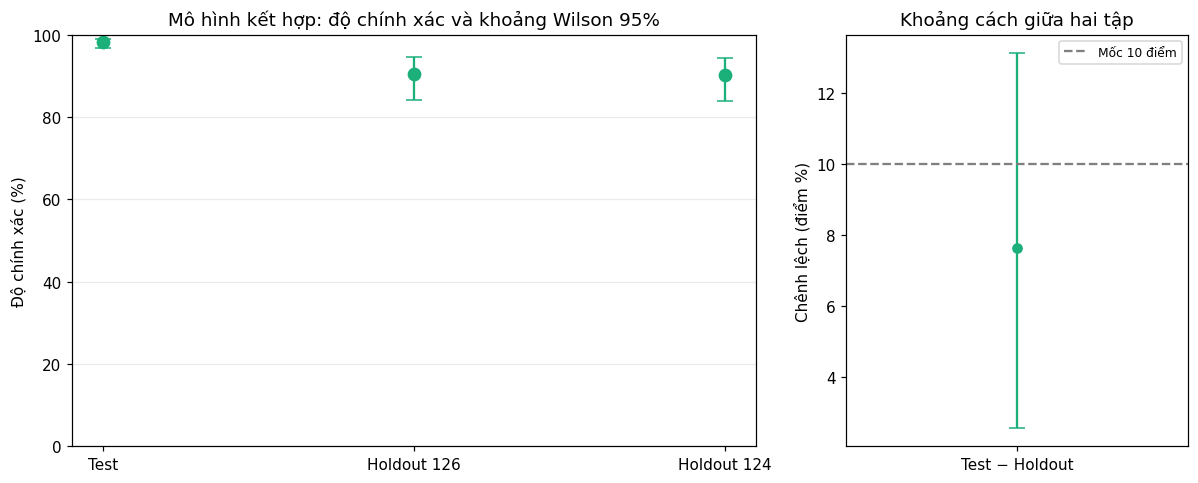

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/01_accuracy_and_gap.png


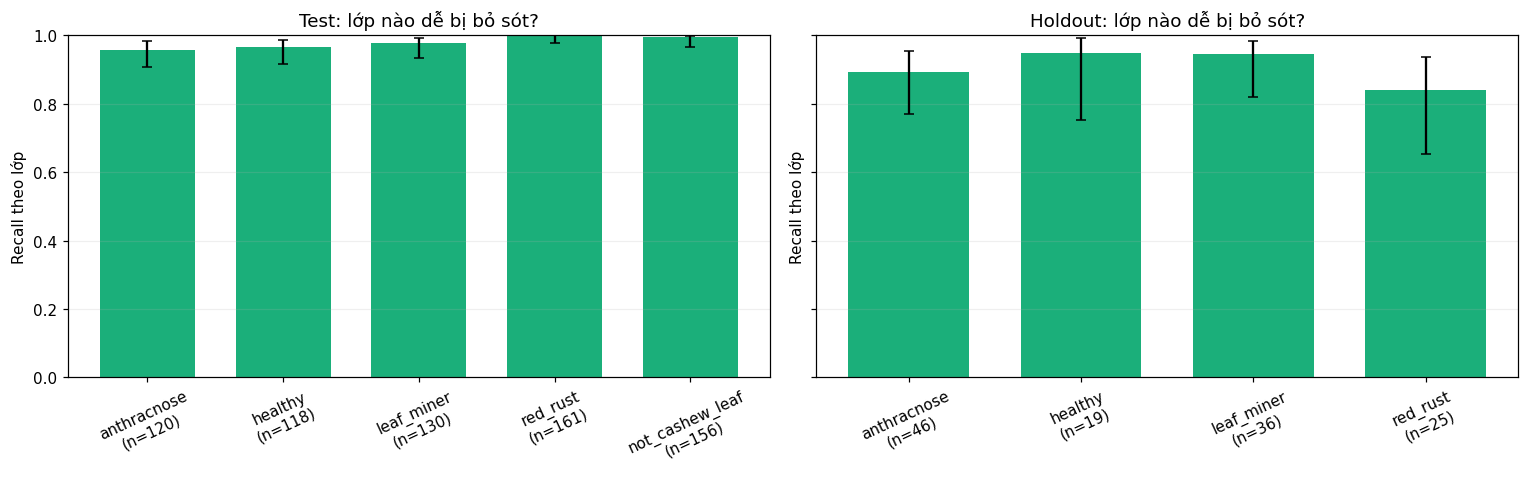

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/02_class_recall.png


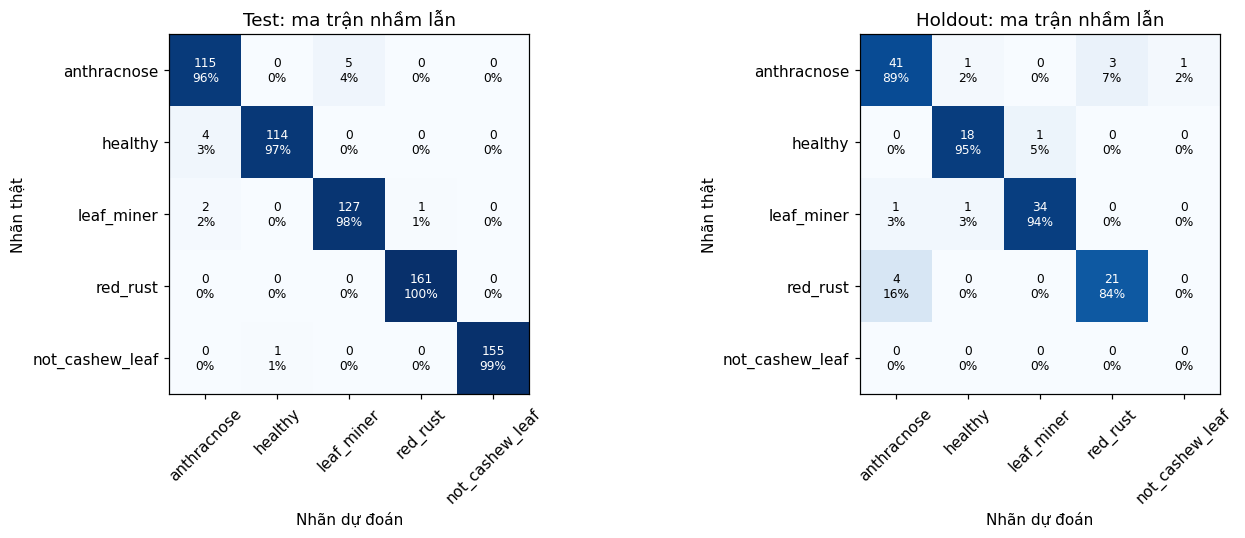

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/03_confusion_matrices.png


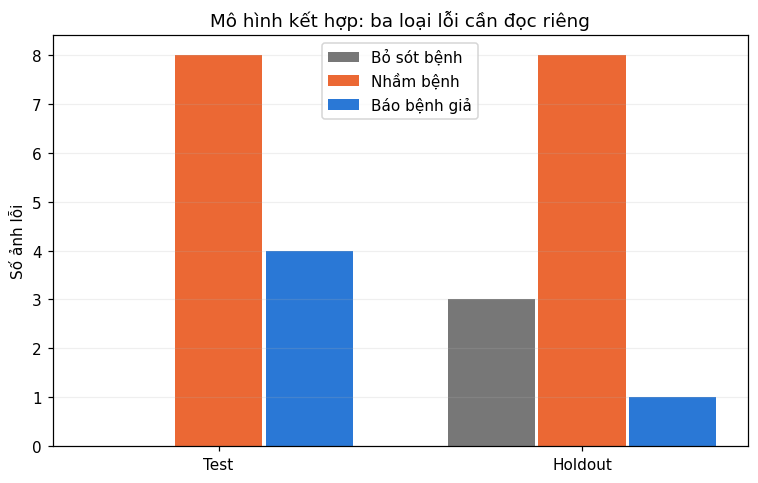

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/04_error_types.png


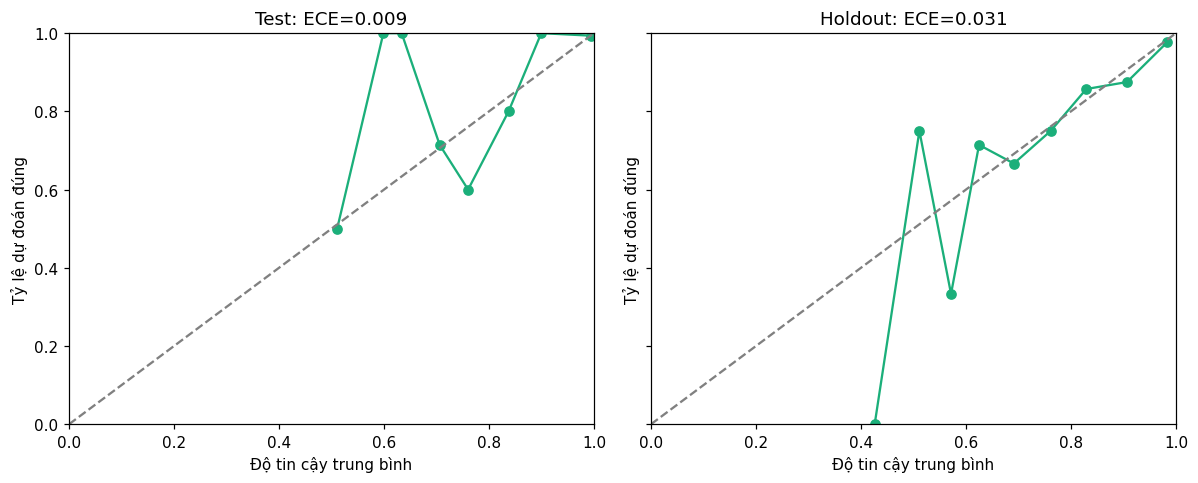

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/05_calibration.png


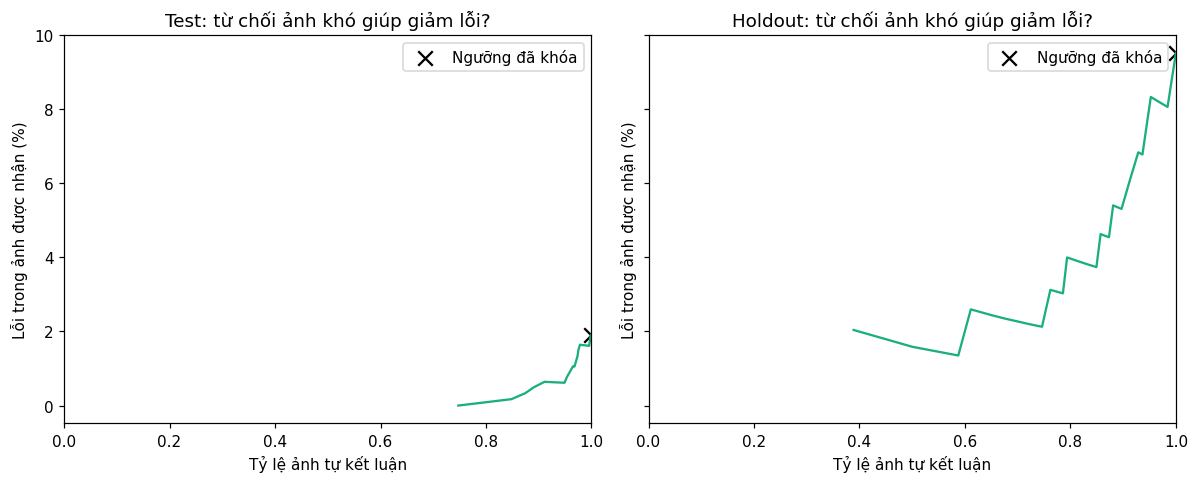

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/06_risk_coverage.png


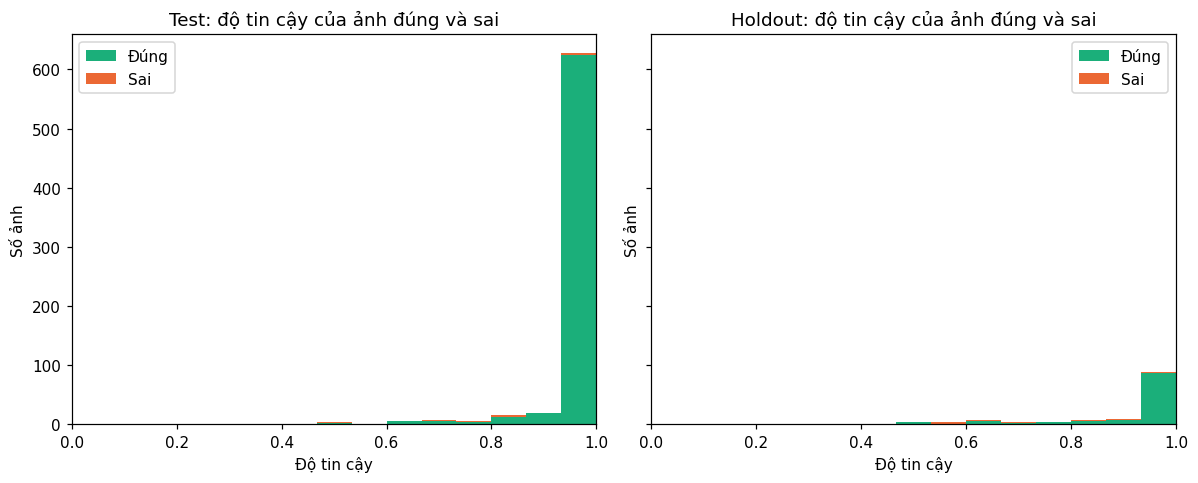

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/07_confidence_distribution.png


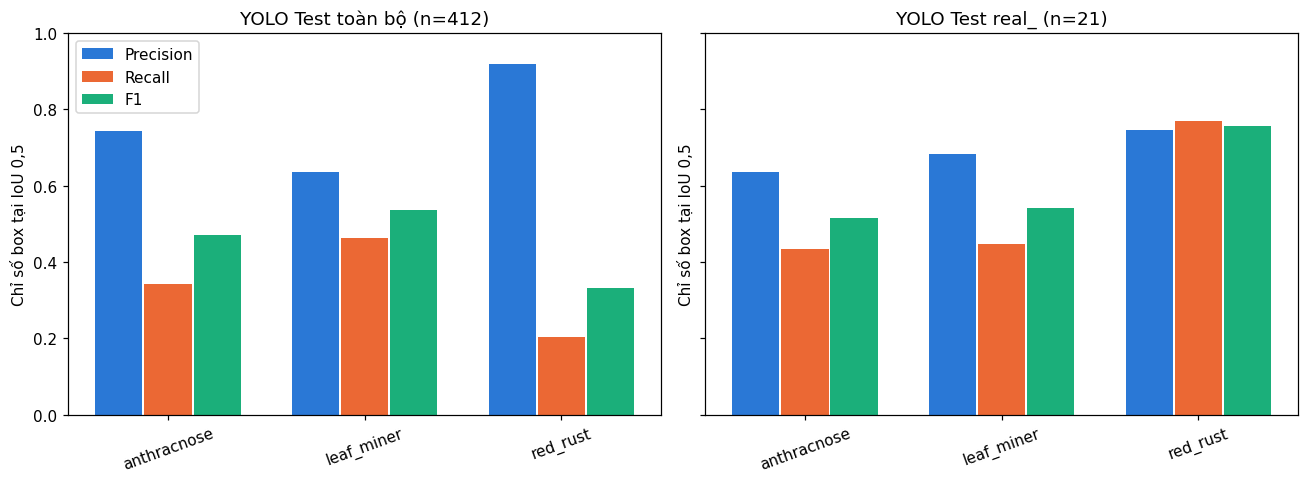

Đã lưu: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only/08_fused_display_localization.png
Chỉ phân tích F3 (ResNet50 + YOLO). Holdout là đánh giá mô tả, không phải blind benchmark.
McNemar cần hai phương pháp trên cùng ảnh nên không áp dụng cho cell chỉ một mô hình.
Ngưỡng từ chối đã khóa: 0.0 | Hình/CSV: /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures/combined_only


In [20]:
# ResNet50 + YOLO only (F3): statistical figures from already computed results.
# Run after the localization/evaluation cell. This cell never fits or selects a model.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

_classes = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
_class_index = {name: i for i, name in enumerate(_classes)}
_root = Path(OUT_DIR) if "OUT_DIR" in globals() else None
if _root is None:
    _candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO*") if (p / "aggregate" / "fusion_results_partB.csv").is_file()]
    if len(_candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-033/033 result folder: {_candidates}")
    _root = _candidates[0]
_aggregate = _root / "aggregate"
_output = _aggregate / "figures" / "combined_only"
_output.mkdir(parents=True, exist_ok=True)

def _read(name):
    path = _aggregate / name
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

_metrics = _read("fusion_results_partB.csv")
if _metrics.empty or not {"F3", "test", "holdout"}.issubset(
        set(_metrics.get("rule", [])) | set(_metrics.get("split", []))):
    raise RuntimeError("Run Part B/EXP-033 evaluation before this figure cell")
_metrics = _metrics[(_metrics.rule == "F3") &
                    (_metrics.split.isin(["test", "holdout", "holdout_n124"]))].copy()
_errors = _read("error_taxonomy.csv")
_errors = _errors[(_errors.part == "B") & (_errors.rule == "F3")]
_risk = _read("risk_coverage.csv")
_risk = _risk[(_risk.part == "B") & (_risk.rule == "F3")]
_abstention = _read("abstention.csv")
_abstention = _abstention[(_abstention.part == "B") & (_abstention.rule == "F3")]
_localization = _read("localization_test.csv")
_config_path = _aggregate / "frozen_config.json"
_config = json.loads(_config_path.read_text(encoding="utf-8")) if _config_path.is_file() else {}
_threshold = _config.get("abstain_thresholds", {}).get("F3")
_color = "#1baf7a"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 10})

def _wilson(correct, total):
    if total == 0:
        return np.nan, np.nan
    z = 1.9599639845
    p = correct / total
    divisor = 1 + z*z/total
    center = (p + z*z/(2*total)) / divisor
    radius = z*np.sqrt((p*(1-p) + z*z/(4*total))/total) / divisor
    return center-radius, center+radius

def _error_magnitudes(mid, low, high):
    """Convert interval bounds to Matplotlib distances, allowing roundoff at 0/1."""
    mid, low, high = np.broadcast_arrays(np.asarray(mid, dtype=float),
                                         np.asarray(low, dtype=float),
                                         np.asarray(high, dtype=float))
    lower = mid - low
    upper = high - mid
    if (not np.isfinite(lower).all() or not np.isfinite(upper).all() or
            np.any(lower < -1e-10) or np.any(upper < -1e-10)):
        raise ValueError(f"Invalid interval bounds: mid={mid}, low={low}, high={high}")
    return np.vstack((np.maximum(0, np.atleast_1d(lower)),
                      np.maximum(0, np.atleast_1d(upper))))

def _save(fig, name):
    fig.tight_layout()
    path = _output / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    print("Đã lưu:", path)

def _predictions(split):
    # The live EXP-033/033 runtime keeps calibrated per-image probabilities.
    if "PART_PREDICTIONS" in globals() and "B" in PART_PREDICTIONS and split in PART_PREDICTIONS["B"]:
        frame, by_rule = PART_PREDICTIONS["B"][split]
        labels, probs = by_rule["F3"]
        result = frame[["evidence_key", "true_label"]].reset_index(drop=True).copy()
        result["predicted_label"] = [_classes[int(i)] for i in labels]
        for i, cls in enumerate(_classes):
            result[f"prob_{cls}"] = probs[:, i]
        return result
    path = _aggregate / f"predictions_{split}_F3.csv"
    return pd.read_csv(path) if path.is_file() else None

_test_pred, _hold_pred = _predictions("test"), _predictions("holdout")
for _split, _frame in (("test", _test_pred), ("holdout", _hold_pred)):
    if _frame is not None:
        if _frame.evidence_key.duplicated().any():
            raise ValueError(f"Duplicate {_split} prediction keys")
        _probs = _frame[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        if not np.isfinite(_probs).all() or not np.allclose(_probs.sum(axis=1), 1, atol=1e-4):
            raise ValueError(f"Invalid {_split} probabilities")
        if not np.array_equal(np.array(_classes)[_probs.argmax(axis=1)],
                              _frame.predicted_label.to_numpy()):
            raise ValueError(f"{_split} labels do not match probabilities")

# Accuracy and Wilson 95% intervals; gap CI uses independent image bootstrap if available.
_acc = _metrics.set_index("split")
_splits = [split for split in ("test", "holdout", "holdout_n124") if split in _acc.index]
_accuracy_rows = []
for _split in _splits:
    _row = _acc.loc[_split]
    _accuracy_rows.append({"split": _split, "n": int(_row.n), "correct": int(_row.correct),
        "accuracy": float(_row.accuracy), "wilson_low": float(_row.wilson_low),
        "wilson_high": float(_row.wilson_high), "ece15": float(_row.ece15)})
_gap = float(_acc.loc["test"].accuracy - _acc.loc["holdout"].accuracy)
_gap_low = _gap_high = np.nan
if _test_pred is not None and _hold_pred is not None:
    _rng = np.random.default_rng(32033)
    _test_ok = (_test_pred.true_label == _test_pred.predicted_label).to_numpy(dtype=float)
    _hold_ok = (_hold_pred.true_label == _hold_pred.predicted_label).to_numpy(dtype=float)
    _ti = _rng.integers(0, len(_test_ok), size=(10000, len(_test_ok)))
    _hi = _rng.integers(0, len(_hold_ok), size=(10000, len(_hold_ok)))
    _distribution = _test_ok[_ti].mean(axis=1) - _hold_ok[_hi].mean(axis=1)
    _gap_low, _gap_high = np.quantile(_distribution, [.025, .975])
pd.DataFrame(_accuracy_rows).to_csv(_output / "accuracy_wilson.csv", index=False)
pd.DataFrame([{"test_minus_holdout": _gap, "bootstrap_low": _gap_low,
               "bootstrap_high": _gap_high, "resamples": 10000 if np.isfinite(_gap_low) else 0}]).to_csv(
                   _output / "test_holdout_gap.csv", index=False)
fig, (ax, gap_ax) = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [2, 1]})
for i, record in enumerate(_accuracy_rows):
    mid = 100 * record["accuracy"]
    ax.errorbar(i, mid, yerr=_error_magnitudes(mid, 100*record["wilson_low"],
                                                100*record["wilson_high"]),
                fmt="o", capsize=5, color=_color, markersize=8)
ax.set(xticks=range(len(_splits)), xticklabels=["Test", "Holdout 126", "Holdout 124"][:len(_splits)],
       ylim=(0, 100), ylabel="Độ chính xác (%)",
       title="Mô hình kết hợp: độ chính xác và khoảng Wilson 95%")
ax.grid(axis="y", alpha=.25)
if np.isfinite(_gap_low):
    gap_ax.errorbar(0, 100*_gap, yerr=_error_magnitudes(100*_gap, 100*_gap_low,
                                                          100*_gap_high),
                    fmt="o", capsize=5, color=_color)
else:
    gap_ax.scatter(0, 100*_gap, color=_color)
    gap_ax.text(.5, .05, "Không có xác suất từng ảnh\nđể tính khoảng bootstrap",
                transform=gap_ax.transAxes, ha="center", fontsize=8)
gap_ax.axhline(10, color="grey", ls="--", label="Mốc 10 điểm")
gap_ax.set(xlim=(-.5, .5), xticks=[0], xticklabels=["Test − Holdout"],
           ylabel="Chênh lệch (điểm %)", title="Khoảng cách giữa hai tập")
gap_ax.legend(fontsize=8)
_save(fig, "01_accuracy_and_gap.png")

# Class recall uses the row support of each saved F3 confusion matrix.
_class_rows = []
for _split in ("test", "holdout"):
    _cm = pd.read_csv(_aggregate / f"confusion_B_{_split}_F3.csv", index_col=0)
    _cm = _cm.reindex(index=_classes, columns=_classes, fill_value=0)
    for _class in _classes:
        _support = int(_cm.loc[_class].sum())
        if _support:
            _correct = int(_cm.loc[_class, _class])
            _low, _high = _wilson(_correct, _support)
            _class_rows.append({"split": _split, "class": _class, "support": _support,
                "correct": _correct, "recall": _correct/_support,
                "wilson_low": _low, "wilson_high": _high})
_class_table = pd.DataFrame(_class_rows)
_class_table.to_csv(_output / "class_recall_wilson.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, _split in zip(axes, ("test", "holdout")):
    _rows = _class_table[_class_table.split == _split]
    x = np.arange(len(_rows))
    ax.bar(x, _rows.recall.to_numpy(), color=_color, width=.7)
    midpoint = _rows.recall.to_numpy(dtype=float)
    ax.errorbar(x, midpoint,
                yerr=_error_magnitudes(midpoint,
                                       _rows.wilson_low.to_numpy(dtype=float),
                                       _rows.wilson_high.to_numpy(dtype=float)),
                fmt="none", ecolor="black", capsize=3)
    ax.set(xticks=x, xticklabels=[f"{r['class']}\n(n={r['support']})" for _, r in _rows.iterrows()],
           ylim=(0, 1), ylabel="Recall theo lớp", title=f"{_split.title()}: lớp nào dễ bị bỏ sót?")
    ax.tick_params(axis="x", labelrotation=25)
    ax.grid(axis="y", alpha=.2)
_save(fig, "02_class_recall.png")

# Confusion matrices show counts and row percentages on a shared 0–100% scale.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, _split in zip(axes, ("test", "holdout")):
    _cm = pd.read_csv(_aggregate / f"confusion_B_{_split}_F3.csv", index_col=0)
    _cm = _cm.reindex(index=_classes, columns=_classes, fill_value=0)
    counts = _cm.to_numpy(dtype=int)
    support = counts.sum(axis=1, keepdims=True)
    frac = np.divide(counts, support, out=np.zeros_like(counts, dtype=float), where=support > 0)
    ax.imshow(frac, cmap="Blues", vmin=0, vmax=1)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{counts[i,j]}\n{frac[i,j]:.0%}", ha="center", va="center",
                    fontsize=8, color="white" if frac[i,j] > .55 else "black")
    ax.set(xticks=range(5), xticklabels=_classes, yticks=range(5), yticklabels=_classes,
           xlabel="Nhãn dự đoán", ylabel="Nhãn thật", title=f"{_split.title()}: ma trận nhầm lẫn")
    ax.tick_params(axis="x", labelrotation=45)
_save(fig, "03_confusion_matrices.png")

_error_rows = _errors[_errors.split.isin(["test", "holdout"])][
    ["split", "missed_disease", "wrong_disease_type", "false_alarm"]].copy()
_error_rows.to_csv(_output / "error_types.csv", index=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
_error_names = [("missed_disease", "Bỏ sót bệnh", "#777777"),
                ("wrong_disease_type", "Nhầm bệnh", "#eb6834"),
                ("false_alarm", "Báo bệnh giả", "#2a78d6")]
for i, (_field, _label, _shade) in enumerate(_error_names):
    ax.bar(np.arange(2) + (i-1)*.25,
           [int(_error_rows[_error_rows.split == s].iloc[0][_field]) for s in ("test", "holdout")],
           width=.24, label=_label, color=_shade)
ax.set(xticks=[0, 1], xticklabels=["Test", "Holdout"], ylabel="Số ảnh lỗi",
       title="Mô hình kết hợp: ba loại lỗi cần đọc riêng")
ax.legend()
ax.grid(axis="y", alpha=.2)
_save(fig, "04_error_types.png")

# A reliability diagram needs per-image probabilities; ECE is still shown when absent.
_bin_rows = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, _split, _pred in zip(axes, ("test", "holdout"), (_test_pred, _hold_pred)):
    _ece = float(_acc.loc[_split].ece15)
    if _pred is not None:
        probs = _pred[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        confidence = probs.max(axis=1)
        correct = (_pred.true_label == _pred.predicted_label).to_numpy()
        x, y = [], []
        for b in range(15):
            low, high = b/15, (b+1)/15
            chosen = (confidence >= low) & ((confidence <= high) if b == 14 else (confidence < high))
            if chosen.any():
                mean_conf, observed = float(confidence[chosen].mean()), float(correct[chosen].mean())
                x.append(mean_conf)
                y.append(observed)
                _bin_rows.append({"split": _split, "bin": b, "n": int(chosen.sum()),
                                  "mean_confidence": mean_conf, "observed_accuracy": observed})
        ax.plot(x, y, "o-", color=_color)
    else:
        ax.text(.5, .5, "Thiếu xác suất từng ảnh\nchỉ có ECE tổng hợp",
                transform=ax.transAxes, ha="center", va="center")
    ax.plot([0, 1], [0, 1], "--", color="grey")
    ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Độ tin cậy trung bình",
           ylabel="Tỷ lệ dự đoán đúng", title=f"{_split.title()}: ECE={_ece:.3f}")
pd.DataFrame(_bin_rows, columns=["split", "bin", "n", "mean_confidence",
    "observed_accuracy"]).to_csv(_output / "reliability_bins.csv", index=False)
_save(fig, "05_calibration.png")

_risk_rows = _risk[_risk.split.isin(["test", "holdout"])][
    ["split", "threshold", "coverage", "risk"]].copy()
_risk_rows.to_csv(_output / "risk_coverage.csv", index=False)
_abstention_rows = _abstention[_abstention.split.isin(["test", "holdout"])][
    ["split", "threshold", "coverage", "selective_accuracy", "referred_to_expert"]].copy()
_abstention_rows.to_csv(_output / "abstention.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, _split in zip(axes, ("test", "holdout")):
    view = _risk_rows[_risk_rows.split == _split].dropna(subset=["risk"])
    ax.plot(view.coverage, 100*view.risk, color=_color)
    point = _abstention_rows[_abstention_rows.split == _split]
    if not point.empty and np.isfinite(point.iloc[0].selective_accuracy):
        ax.scatter(point.iloc[0].coverage, 100*(1-point.iloc[0].selective_accuracy),
                   marker="x", color="black", s=90, label="Ngưỡng đã khóa")
    ax.set(xlim=(0, 1), xlabel="Tỷ lệ ảnh tự kết luận",
           ylabel="Lỗi trong ảnh được nhận (%)",
           title=f"{_split.title()}: từ chối ảnh khó giúp giảm lỗi?")
    ax.legend()
_save(fig, "06_risk_coverage.png")

if _test_pred is not None and _hold_pred is not None:
    _confidence_rows = []
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
    for ax, _split, _pred in zip(axes, ("test", "holdout"), (_test_pred, _hold_pred)):
        probs = _pred[[f"prob_{name}" for name in _classes]].to_numpy(dtype=float)
        confidence = probs.max(axis=1)
        correct = (_pred.true_label == _pred.predicted_label).to_numpy()
        _confidence_rows.extend({"split": _split, "evidence_key": key,
            "confidence": float(q), "correct": bool(ok)}
            for key, q, ok in zip(_pred.evidence_key, confidence, correct))
        ax.hist([confidence[correct], confidence[~correct]], bins=np.linspace(0, 1, 16),
                stacked=True, color=[_color, "#eb6834"], label=["Đúng", "Sai"])
        ax.set(xlim=(0, 1), xlabel="Độ tin cậy", ylabel="Số ảnh",
               title=f"{_split.title()}: độ tin cậy của ảnh đúng và sai")
        ax.legend()
    pd.DataFrame(_confidence_rows).to_csv(_output / "confidence_by_image.csv", index=False)
    _save(fig, "07_confidence_distribution.png")

_selected = globals().get("SELECTED_DEFAULT")
if _selected is None and (_aggregate / "exp033_summary.json").is_file():
    _selected = "F3"  # EXP-033 summary declares the combined method.
if _selected == "F3" and not _localization.empty and "mode" in _localization.columns:
    _loc = _localization[(_localization["mode"] == "fused_display") &
                         (_localization["subset"].isin(["all", "real_"]))].copy()
    if not _loc.empty:
        _loc.to_csv(_output / "fused_display_localization.csv", index=False)
        fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
        for ax, subset in zip(axes, ("all", "real_")):
            view = _loc[_loc["subset"] == subset].set_index("class")
            names = [cls for cls in ("anthracnose", "leaf_miner", "red_rust") if cls in view.index]
            x = np.arange(len(names))
            for i, (field, label, shade) in enumerate((
                    ("precision50", "Precision", "#2a78d6"),
                    ("recall50", "Recall", "#eb6834"),
                    ("f1_50", "F1", "#1baf7a"))):
                ax.bar(x + (i-1)*.25, view.loc[names, field].to_numpy(dtype=float),
                       width=.24, label=label, color=shade)
            count = int(view.images.iloc[0]) if len(view) else 0
            ax.set(xticks=x, xticklabels=names, ylim=(0, 1),
                   ylabel="Chỉ số box tại IoU 0,5",
                   title=f"YOLO Test {'real_' if subset == 'real_' else 'toàn bộ'} (n={count})")
            ax.tick_params(axis="x", labelrotation=20)
        axes[0].legend()
        _save(fig, "08_fused_display_localization.png")
else:
    print("Bỏ qua hình định vị: bảng fused_display hiện có không được xác nhận là của F3.")

print("Chỉ phân tích F3 (ResNet50 + YOLO). Holdout là đánh giá mô tả, không phải blind benchmark.")
print("McNemar cần hai phương pháp trên cùng ảnh nên không áp dụng cho cell chỉ một mô hình.")
print("Ngưỡng từ chối đã khóa:", _threshold, "| Hình/CSV:", _output)


In [21]:
PIPELINE_MODULE_SOURCE = '"""Standalone EXP-033 Cashew + YOLO pipeline. Generated from notebook source."""\nimport json\nfrom pathlib import Path\nimport joblib\nimport numpy as np\nimport tensorflow as tf\nfrom tensorflow import keras\nfrom tensorflow.keras import layers\nfrom PIL import Image, ImageOps\n\nSTAGE2_UNFREEZE_PREFIX = "conv5_block3"\n\n@keras.utils.register_keras_serializable(package="exp029", name="RandomHSVJitter")\nclass RandomHSVJitter(layers.Layer):\n    """Per-image saturation scaling, hue shift and random grayscale.\n\n    Active only when training=True so the Validation/Test/holdout path stays\n    a pure identity, which the smoke test below asserts.\n    """\n\n    def __init__(self, saturation_range=(0.6, 1.4), hue_delta=0.03,\n                 grayscale_probability=0.10, value_range=(0.0, 255.0),\n                 seed=None, **kwargs):\n        super().__init__(**kwargs)\n        if not (0.0 < saturation_range[0] <= 1.0 <= saturation_range[1]):\n            raise ValueError("saturation_range must bracket 1.0")\n        if not 0.0 <= hue_delta <= 0.5:\n            raise ValueError("hue_delta must be within [0, 0.5]")\n        if not 0.0 <= grayscale_probability <= 1.0:\n            raise ValueError("grayscale_probability must be within [0, 1]")\n        self.saturation_range = tuple(float(v) for v in saturation_range)\n        self.hue_delta = float(hue_delta)\n        self.grayscale_probability = float(grayscale_probability)\n        self.value_range = tuple(float(v) for v in value_range)\n        self.seed = seed\n        self.seed_generator = keras.random.SeedGenerator(seed)\n\n    def call(self, inputs, training=False):\n        if not training:\n            return inputs\n        low, high = self.value_range\n        span = high - low\n        normalized = tf.clip_by_value((inputs - low) / span, 0.0, 1.0)\n        batch = tf.shape(normalized)[0]\n        saturation = keras.random.uniform(\n            (batch, 1, 1), self.saturation_range[0], self.saturation_range[1],\n            seed=self.seed_generator)\n        grayscale_draw = keras.random.uniform(\n            (batch, 1, 1), 0.0, 1.0, seed=self.seed_generator)\n        saturation = tf.where(grayscale_draw < self.grayscale_probability,\n                              tf.zeros_like(saturation), saturation)\n        hue_shift = keras.random.uniform(\n            (batch, 1, 1), -self.hue_delta, self.hue_delta, seed=self.seed_generator)\n        hsv = tf.image.rgb_to_hsv(normalized)\n        hue = tf.math.floormod(hsv[..., 0] + hue_shift, 1.0)\n        sat = tf.clip_by_value(hsv[..., 1] * saturation, 0.0, 1.0)\n        value = hsv[..., 2]\n        converted = tf.image.hsv_to_rgb(tf.stack([hue, sat, value], axis=-1))\n        return tf.clip_by_value(converted * span + low, low, high)\n\n    def compute_output_shape(self, input_shape):\n        return input_shape\n\n    def get_config(self):\n        config = super().get_config()\n        config.update({"saturation_range": list(self.saturation_range),\n                       "hue_delta": self.hue_delta,\n                       "grayscale_probability": self.grayscale_probability,\n                       "value_range": list(self.value_range),\n                       "seed": self.seed})\n        return config\n\n\n@keras.utils.register_keras_serializable(package="resnet50", name="CaffeBGRPreprocess")\nclass CaffeBGRPreprocess(layers.Layer):\n    MEAN_BGR = (103.939, 116.779, 123.68)\n    def call(self, inputs):\n        return tf.reverse(inputs, axis=[-1]) - tf.constant(self.MEAN_BGR, dtype=inputs.dtype)\n    def compute_output_shape(self, input_shape):\n        return input_shape\n\n\nclass CashewPipeline:\n    def __init__(self,bundle_dir):\n        self.bundle_dir=Path(bundle_dir)\n        self.config=json.loads((self.bundle_dir/"frozen_config.json").read_text(encoding="utf-8"))\n        self.classes=self.config["classes"]\n        self.detector_classes=self.config["detector_classes"]\n        self.models=[keras.models.load_model(self.bundle_dir/f"seed_{seed}"/"deployment_model.keras")\n                     for seed in self.config["seeds"]]\n        self.stackers=joblib.load(self.bundle_dir/"stacker.joblib")\n        self.rule=json.loads((self.bundle_dir/"decision.json").read_text(encoding="utf-8"))["selected_default_rule"]\n        if self.config.get("dry_run_stub_detector"):\n            self.detector=None\n        else:\n            from ultralytics import YOLO\n            self.detector=YOLO(str(self.bundle_dir/"best.pt"))\n\n    @staticmethod\n    def _iou(a,b):\n        x1,y1,x2,y2=max(a[0],b[0]),max(a[1],b[1]),min(a[2],b[2]),min(a[3],b[3])\n        inter=max(0,x2-x1)*max(0,y2-y1)\n        aa=max(0,a[2]-a[0])*max(0,a[3]-a[1]);bb=max(0,b[2]-b[0])*max(0,b[3]-b[1])\n        return inter/(aa+bb-inter) if aa+bb>inter else 0.0\n\n    def _boxes(self,image,path):\n        height,width=image.shape[:2]\n        if self.detector is None:\n            if path is None or np.std(image)==0:\n                return [],(height,width)\n            name=Path(path).parent.name\n            cls=(self.detector_classes.index(name) if name in self.detector_classes else 0)\n            return ([{"cls":self.detector_classes[cls],"conf":.75,\n                     "xyxy":[width*.3,height*.3,width*.7,height*.7]}],(height,width))\n        source=str(path) if path is not None else image\n        result=self.detector.predict(source,conf=.05,iou=.7,imgsz=640,rect=False,verbose=False)[0]\n        boxes=[{"cls":self.detector_classes[int(c)],"conf":float(q),"xyxy":xy.tolist()}\n               for c,q,xy in zip(result.boxes.cls.cpu().numpy(),result.boxes.conf.cpu().numpy(),\n                                 result.boxes.xyxy.cpu().numpy())]\n        return boxes,tuple(result.orig_shape)\n\n    def predict(self,image_path_or_array):\n        path=Path(image_path_or_array) if isinstance(image_path_or_array,(str,Path)) else None\n        if path is not None:\n            # Match make_dataset: tf.io.decode_image does not apply PIL EXIF transpose.\n            image=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,\n                                     expand_animations=False).numpy()\n        else:\n            image=np.asarray(image_path_or_array)\n            if image.ndim==2: image=np.repeat(image[...,None],3,axis=2)\n            elif image.ndim==3 and image.shape[2]==1: image=np.repeat(image,3,axis=2)\n            elif image.ndim==3 and image.shape[2]==4: image=image[:,:,:3]\n            if image.ndim!=3 or image.shape[2]!=3: raise ValueError("Expected RGB or grayscale image")\n            image=np.clip(image,0,255).astype(np.uint8)\n        resized=tf.image.resize(tf.cast(image,tf.float32),(256,256)).numpy()[None,...]\n        p=np.mean([model.predict(resized,verbose=0)[0] for model in self.models],axis=0)\n        boxes,(h,w)=self._boxes(image,path)\n        evidence={"max_conf":{},"n_boxes":{},"area_frac":{}}\n        for cls in self.detector_classes:\n            subset=[b for b in boxes if b["cls"]==cls]\n            evidence["max_conf"][cls]=max([b["conf"] for b in subset],default=0.0)\n            evidence["n_boxes"][cls]=len(subset)\n            evidence["area_frac"][cls]=min(sum((b["xyxy"][2]-b["xyxy"][0])*\n                 (b["xyxy"][3]-b["xyxy"][1]) for b in subset)/(w*h),1.0)\n        feature=np.array(list(p)+[evidence[prefix][cls] for prefix in\n                     ("max_conf","n_boxes","area_frac") for cls in self.detector_classes],dtype=float)\n        if self.rule in ("F1","F2"):\n            threshold=float(self.config["tau_selection"]["tau"]) if self.rule=="F1" else .05\n            rank=np.argsort(-p)\n            if rank[0]==self.classes.index("anthracnose") and evidence["max_conf"]["anthracnose"]<threshold:\n                p[rank[0]],p[rank[1]]=p[rank[1]],p[rank[0]]\n        elif self.rule in ("F3","F3a","F3b"):\n            data=feature[None,:] if self.rule=="F3" else (feature[None,:5] if self.rule=="F3a" else feature[None,5:])\n            model=self.stackers[self.rule]\n            fitted=model.predict_proba(data)[0]\n            p=np.zeros(len(self.classes));p[model[-1].classes_]=fitted\n        temperature=self.config["temperature"][self.rule]\n        p=np.clip(p,1e-9,1)**(1/temperature);p=p/p.sum()\n        order=np.argsort(-p);label=self.classes[order[0]]\n        abstain=bool(p[order[0]]<self.config["abstain_thresholds"][self.rule])\n        shown=[]\n        if not abstain and label in self.detector_classes:\n            for box in sorted((b for b in boxes if b["cls"]==label and b["conf"]>=self.config["box_conf"]),\n                              key=lambda b:-b["conf"]):\n                if all(self._iou(box["xyxy"],old["xyxy"])<=.5 for old in shown):\n                    shown.append(box)\n                if len(shown)>=20: break\n        return {"label":label,"confidence":float(p[order[0]]),\n                "top2":[(self.classes[i],float(p[i])) for i in order[:2]],\n                "abstain":abstain,"probs":{name:float(p[i]) for i,name in enumerate(self.classes)},\n                "evidence":evidence,"boxes":shown,"rule":self.rule,"version":"EXP-033",\n                "action":"expert review" if abstain else "predict"}\n'
# Export and hard consistency check. The module source is embedded by the build script.
if RUN_PART_B:
    module_path=OUT_DIR/"cashew_pipeline.py"
    module_path.write_text(PIPELINE_MODULE_SOURCE,encoding="utf-8")
    import importlib.util
    spec=importlib.util.spec_from_file_location("cashew_pipeline",module_path)
    pipeline_module=importlib.util.module_from_spec(spec);sys.modules[spec.name]=pipeline_module
    spec.loader.exec_module(pipeline_module)
    bundle=OUT_DIR/"pipeline_bundle"
    bundle.mkdir(exist_ok=True)
    shutil.copy2(module_path,bundle/"cashew_pipeline.py")
    for seed in SEEDS:
        target=bundle/f"seed_{seed}"
        target.mkdir(exist_ok=True)
        shutil.copy2(OUT_DIR/f"seed_{seed}"/"deployment_model.keras",target/"deployment_model.keras")
    if not DRY_RUN:
        shutil.copy2(DETECTOR_WEIGHTS_PATH,bundle/"best.pt")
        assert file_sha256(bundle/"best.pt")==DETECTOR_WEIGHTS_SHA256
    shutil.copy2(AGGREGATE/"stacker.joblib",bundle/"stacker.joblib")
    shutil.copy2(AGGREGATE/"frozen_config.json",bundle/"frozen_config.json")
    write_json(bundle/"decision.json",{"selected_default_rule":SELECTED_DEFAULT,
        "rule":"Predeclared Part B decision conditions; not selected by maximum Holdout score"})
    # The dry-run detector stub is explicit and never enters a real bundle.
    if DRY_RUN:
        frozen=json.loads((bundle/"frozen_config.json").read_text(encoding="utf-8"))
        frozen["dry_run_stub_detector"]=True
        write_json(bundle/"frozen_config.json",frozen)
    files=[p for p in bundle.rglob("*") if p.is_file()]
    pd.DataFrame([{"path":p.relative_to(bundle).as_posix(),"bytes":p.stat().st_size,
                   "sha256":file_sha256(p)} for p in files]).to_csv(bundle/"artifact_sha256.csv",index=False)
    pipeline=pipeline_module.CashewPipeline(bundle)
    hold_frame,hold_predictions=PART_PREDICTIONS["B"]["holdout"]
    selected_rule=SELECTED_DEFAULT
    fixed_keys=sorted(hold_frame.evidence_key)[:min(20,len(hold_frame))]
    for key in fixed_keys:
        path=INVENTORY["holdout"].set_index("evidence_key").loc[key,"path"]
        actual=pipeline.predict(path)
        one=hold_frame[hold_frame.evidence_key==key]
        expected=apply_temperature(rule_probs(one,selected_rule,modelsB),
                                   configB["temperature"][selected_rule])[0]
        assert actual["label"]==CLASSES[int(np.argmax(expected))]
        if not np.allclose([actual["probs"][c] for c in CLASSES],expected,atol=1e-4):
            resnet_batch=one[PROB_COLUMNS].to_numpy(dtype=float)[0]
            raw=tf.io.decode_image(tf.io.read_file(str(path)),channels=3,
                                   expand_animations=False)
            resized=tf.image.resize(tf.cast(raw,tf.float32),(IMG_SIZE,IMG_SIZE)).numpy()[None,...]
            resnet_single=np.mean([model.predict(resized,verbose=0)[0] for model in pipeline.models],axis=0)
            evidence_batch={name:{cls:float(one.iloc[0][f"{name}_{cls}"])
                                  for cls in DETECTOR_CLASSES}
                            for name in ("max_conf","n_boxes","area_frac")}
            raise AssertionError(
                f"Pipeline probabilities differ for {key}; "
                f"resnet_max_abs={np.max(np.abs(resnet_single-resnet_batch)):.6g}; "
                f"resnet_batch={resnet_batch}; resnet_single={resnet_single}; "
                f"evidence_batch={evidence_batch}; evidence_single={actual['evidence']}; "
                f"final_batch={expected}; final_single={[actual['probs'][c] for c in CLASSES]}")
        stored=BOX_FRAMES["holdout"][BOX_FRAMES["holdout"].evidence_key==key]
        expected_boxes=display_boxes(stored,BOX_CONF,actual["label"],actual["abstain"])
        assert len(actual["boxes"])==len(expected_boxes)
        for left,right in zip(actual["boxes"],expected_boxes):
            assert left["cls"]==right["cls"] and abs(left["conf"]-right["conf"])<1e-4
            assert np.allclose(left["xyxy"],right["xyxy"],atol=1e-4)
    old_detector=pipeline.detector
    pipeline.detector=None
    assert pipeline.predict(np.zeros((48,48,3),dtype=np.uint8))["boxes"]==[]
    pipeline.detector=old_detector
    assert isinstance(pipeline.predict(np.full((48,48),128,dtype=np.uint8))["label"],str)
    print("Pipeline consistency PASS",len(fixed_keys),"Holdout images + no-detection + grayscale")

    for cls in CLASSES[:4]:
        subset=INVENTORY["holdout"][INVENTORY["holdout"].true_label==cls].sort_values("evidence_key").head(6)
        panel=Image.new("RGB",(3*256,2*288),"white")
        for i,row in enumerate(subset.itertuples()):
            with Image.open(row.path) as handle:
                image=ImageOps.exif_transpose(handle).convert("RGB")
            output=pipeline.predict(row.path)
            draw=ImageDraw.Draw(image)
            for box in output["boxes"]:
                draw.rectangle(box["xyxy"],outline="red",width=3)
                draw.text(box["xyxy"][:2],f"{box['cls']} {box['conf']:.2f}",fill="red")
            image.thumbnail((256,256))
            x=(i%3)*256;y=(i//3)*288
            panel.paste(image,(x,y))
            ImageDraw.Draw(panel).text((x,y+258),f"{output['label']} {output['confidence']:.2f}",fill="black")
        panel.save(AGGREGATE/f"qualitative_holdout_{cls}.png")
    print("Holdout panels: descriptive audit, not a blind benchmark")

    # The parent has already checked the full five-model + YOLO pipeline on
    # Holdout images. This fresh process isolates Keras deserialization of one
    # exported model; loading all five models plus YOLO again can exhaust or
    # crash a Colab runtime at the native-library level.
    probe = """import faulthandler, sys
from pathlib import Path
faulthandler.enable()
print('stage=import_module', flush=True)
sys.path.insert(0, sys.argv[1])
from cashew_pipeline import RandomHSVJitter, CaffeBGRPreprocess
from tensorflow import keras
import numpy as np
print('stage=load_model', flush=True)
model = keras.models.load_model(Path(sys.argv[1]) / f'seed_{sys.argv[2]}' / 'deployment_model.keras', compile=False)
print('stage=predict', flush=True)
probs = model(np.zeros((1, 256, 256, 3), dtype=np.float32), training=False).numpy()
assert probs.shape == (1, 5) and np.isfinite(probs).all()
assert np.allclose(probs.sum(axis=1), 1.0, atol=1e-4)
print('stage=PASS', flush=True)
"""
    probe_env = os.environ.copy()
    probe_env.update({"CUDA_VISIBLE_DEVICES": "-1", "OMP_NUM_THREADS": "1",
                      "OPENBLAS_NUM_THREADS": "1", "MKL_NUM_THREADS": "1",
                      "TF_NUM_INTRAOP_THREADS": "1", "TF_NUM_INTEROP_THREADS": "1",
                      "TF_ENABLE_ONEDNN_OPTS": "0", "PYTHONFAULTHANDLER": "1"})
    fresh = subprocess.run([sys.executable, "-X", "faulthandler", "-c", probe,
                            str(bundle), str(SEEDS[0])],
                           check=False, capture_output=True, text=True,
                           errors="replace", env=probe_env, timeout=180)
    write_json(AGGREGATE / "fresh_process_reload.json", {
        "returncode": fresh.returncode, "stdout": fresh.stdout,
        "stderr_tail": fresh.stderr[-12000:],
        "scope": "one exported Keras model and both registered custom layers"})
    if fresh.returncode != 0:
        raise RuntimeError(
            f"Fresh-process model reload failed (returncode {fresh.returncode}). "
            f"Last stage and native traceback:\n{fresh.stdout}\n{fresh.stderr[-12000:]}")
    print("Fresh-process model reload PASS:", fresh.stdout.strip())
    latency_paths = INVENTORY["validation"].path.head(min(10, len(INVENTORY["validation"]))).tolist()
    timings = []
    for image_path in latency_paths:
        started = time.perf_counter()
        pipeline.predict(image_path)
        timings.append((time.perf_counter() - started) * 1000)
    write_json(AGGREGATE / "pipeline_latency_batch1.json", {
        "hardware": platform.platform(), "tensorflow": tf.__version__,
        "gpu": [str(x) for x in tf.config.list_physical_devices("GPU")],
        "n": len(timings), "mean_ms": float(np.mean(timings)),
        "median_ms": float(np.median(timings)),
        "scope": "YOLO + five-seed classifier + fusion; same machine"})


Pipeline consistency PASS 20 Holdout images + no-detection + grayscale
Holdout panels: descriptive audit, not a blind benchmark
Fresh-process model reload PASS: stage=import_module
stage=load_model
stage=predict
stage=PASS


In [22]:
# V2: per-image, per-seed, per-rule predictions, with the pinned dataset hash.
def export_seed_rule_predictions(part, models, config):
    directory = AGGREGATE / "predictions" / f"part{part}"
    for split in ("validation", "test", "holdout"):
        for seed in SEEDS:
            source_path = (OUT_DIR / "partA_seed_predictions" / f"{split}_seed_{seed}.csv"
                           if part == "A" else OUT_DIR / f"seed_{seed}" / f"{split}_predictions.csv")
            frame = pd.read_csv(source_path)
            frame = assemble(frame, split)
            if split == "validation":
                frame = frame[frame.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
            truth = frame.true_label.map(CLASS_INDEX).to_numpy()
            for rule in RULES:
                probs = apply_temperature(rule_probs(frame, rule, models), config["temperature"][rule])
                pred = probs.argmax(1)
                output = pd.DataFrame({"experiment_id": EXPERIMENT_ID, "part": part,
                    "seed": seed, "split": "validation_clean" if split == "validation" else split,
                    "image_id": frame.evidence_key.to_numpy(),
                    "dataset_sha256": DATASET_ARCHIVE_SHA256,
                    "true_label": frame.true_label.to_numpy(),
                    "predicted_label": [CLASSES[i] for i in pred],
                    "correct": pred == truth, "confidence": probs.max(1), "rule": rule})
                for j, name in enumerate(CLASSES):
                    output[f"prob_{name}"] = probs[:, j]
                destination = directory / ("validation_clean" if split == "validation" else split)
                destination.mkdir(parents=True, exist_ok=True)
                output.to_csv(destination / f"seed_{seed}_{rule}.csv", index=False)

if RUN_PART_A:
    export_seed_rule_predictions("A", modelsA, configA)
if RUN_PART_B:
    export_seed_rule_predictions("B", modelsB, configB)


In [23]:
# Optional, exploratory ResNet50 031 sensitivity with its pinned ANALYSIS ZIP.
if RUN_PART_A_031_SENSITIVITY:
    if not RUN_PART_A or not SENSITIVITY_031_ANALYSIS_OVERRIDE:
        raise RuntimeError("Enable Part A and set SENSITIVITY_031_ANALYSIS_OVERRIDE")
    sensitivity_zip = Path(SENSITIVITY_031_ANALYSIS_OVERRIDE)
    if file_sha256(sensitivity_zip) != SENSITIVITY_031_ANALYSIS_SHA256:
        raise RuntimeError("ResNet50 031 ANALYSIS ZIP SHA256 mismatch")
    with zipfile.ZipFile(sensitivity_zip) as archive:
        if archive.testzip() is not None:
            raise RuntimeError("Corrupt ResNet50 031 ANALYSIS ZIP")
        members = [n for n in archive.namelist() if n.endswith("predictions_standard.csv")]
        if len(members) != 15:
            raise RuntimeError(f"Expected 15 ResNet50 031 CSVs, found {len(members)}")

    sensitivity_dir = OUT_DIR / "partA031_seed_predictions"
    sensitivity_dir.mkdir(parents=True, exist_ok=True)

    def load_031(split):
        if split in ("test", "holdout") and not (AGGREGATE / "frozen_config_partA031_exploratory.json").is_file():
            raise RuntimeError("Freeze 031 exploratory config before Test/Holdout")
        frames = []
        with zipfile.ZipFile(sensitivity_zip) as archive:
            for seed in SEEDS:
                suffix = (f"/real_holdout/seed_{seed}/predictions_standard.csv" if split == "holdout"
                          else f"/seed_{seed}/{split}/predictions_standard.csv")
                matches = [n for n in members if n.endswith(suffix)]
                if len(matches) != 1:
                    raise RuntimeError(f"ResNet50 031 CSV missing or ambiguous: {suffix}")
                raw = pd.read_csv(io.BytesIO(archive.read(matches[0])))
                if set(raw.dataset_sha256.astype(str).str.lower()) != {DATASET_ARCHIVE_SHA256}:
                    raise RuntimeError("ResNet50 031 dataset hash mismatch")
                if set(raw.seed.astype(int)) != {seed}:
                    raise RuntimeError("ResNet50 031 seed mismatch")
                frame = raw[["true_label"] + PROB_COLUMNS].copy()
                frame.insert(0, "evidence_key", raw.image_id.map(lambda x: split + "/" +
                    "/".join(str(x).replace("\\", "/").split("/")[-2:])))
                frame["seed"] = seed
                unique_keys(frame, "ResNet50 031 exploratory")
                if set(frame.evidence_key) != set(INVENTORY[split].evidence_key):
                    raise RuntimeError("ResNet50 031 inventory mismatch")
                if not np.isfinite(frame[PROB_COLUMNS].to_numpy(dtype=float)).all():
                    raise RuntimeError("ResNet50 031 nonfinite probability")
                if not np.allclose(frame[PROB_COLUMNS].sum(axis=1), 1, atol=1e-4):
                    raise RuntimeError("ResNet50 031 probabilities do not sum to one")
                frame.to_csv(sensitivity_dir / f"{split}_seed_{seed}.csv", index=False)
                frames.append(frame.set_index("evidence_key"))
        ensemble = INVENTORY[split][["evidence_key", "true_label"]].copy()
        for cls in CLASSES:
            ensemble[f"prob_{cls}"] = np.mean([
                f.loc[ensemble.evidence_key, f"prob_{cls}"].to_numpy(dtype=float) for f in frames], axis=0)
        return ensemble

    original_tau = TAU
    validation_031 = load_031("validation")
    select_tau_from_clean_validation(sensitivity_dir, "_031")
    clean_031 = assemble(validation_031, "validation")
    clean_031 = clean_031[clean_031.evidence_key.isin(CLEAN_VAL_KEYS)].copy()
    models_031, choice_031 = fit_stackers(clean_031, "A031_exploratory")
    config_031 = freeze_fusion("A031_exploratory", clean_031, models_031, choice_031)
    test_031 = assemble(load_031("test"), "test")
    holdout_031 = assemble(load_031("holdout"), "holdout")
    evaluate_part("A031_exploratory", clean_031, test_031, holdout_031, models_031, config_031)
    pd.DataFrame([r for r in ALL_RESULTS if r["part"] == "A031_exploratory"]).to_csv(
        AGGREGATE / "fusion_results_partA031_exploratory.csv", index=False)
    TAU = original_tau


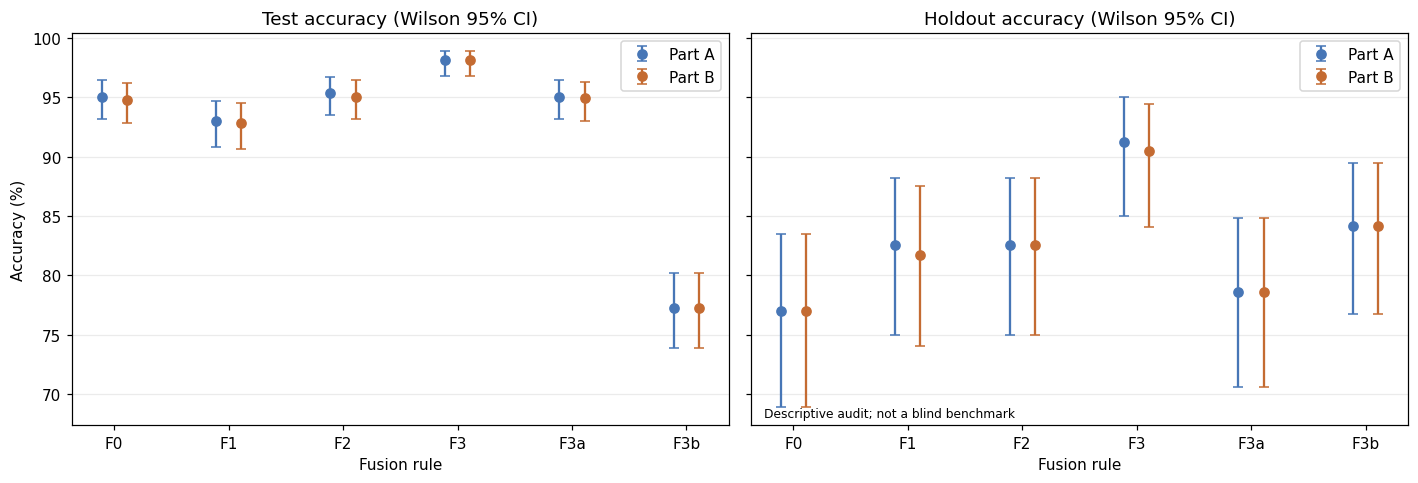

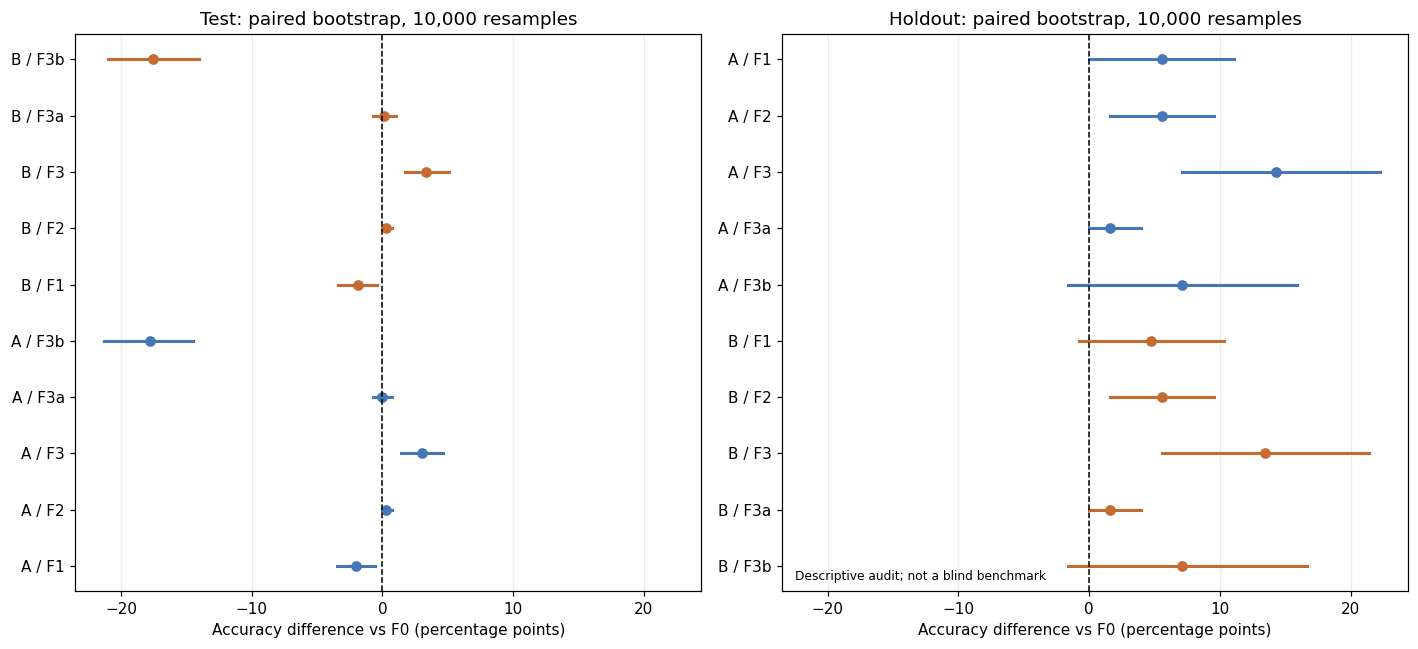

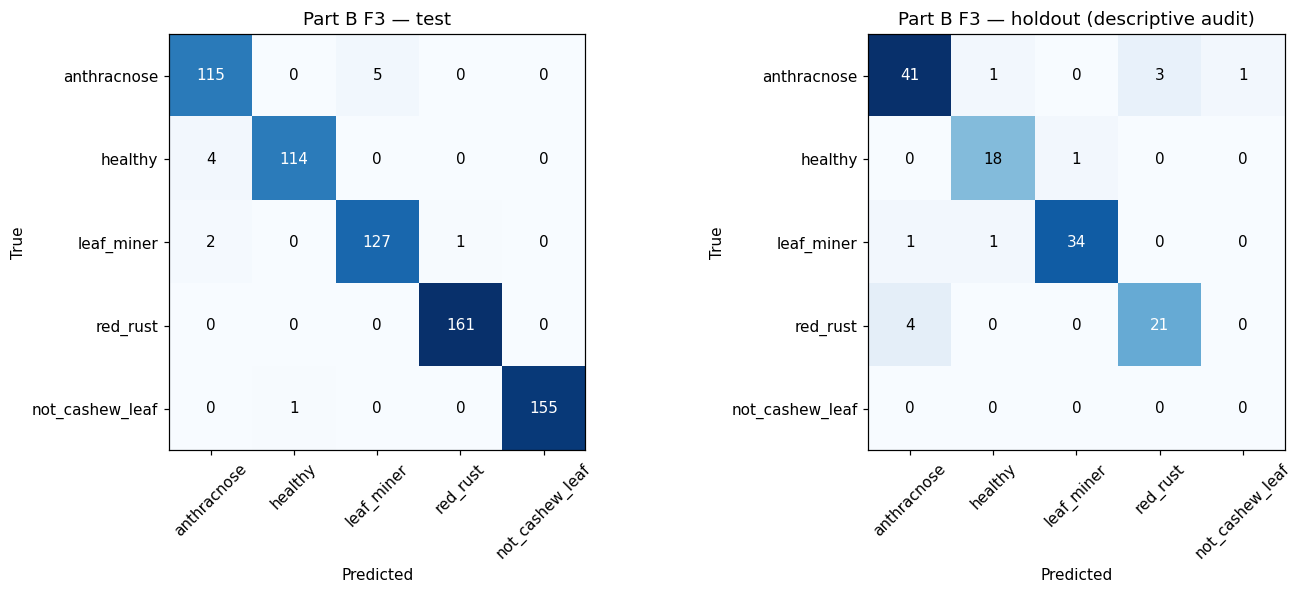

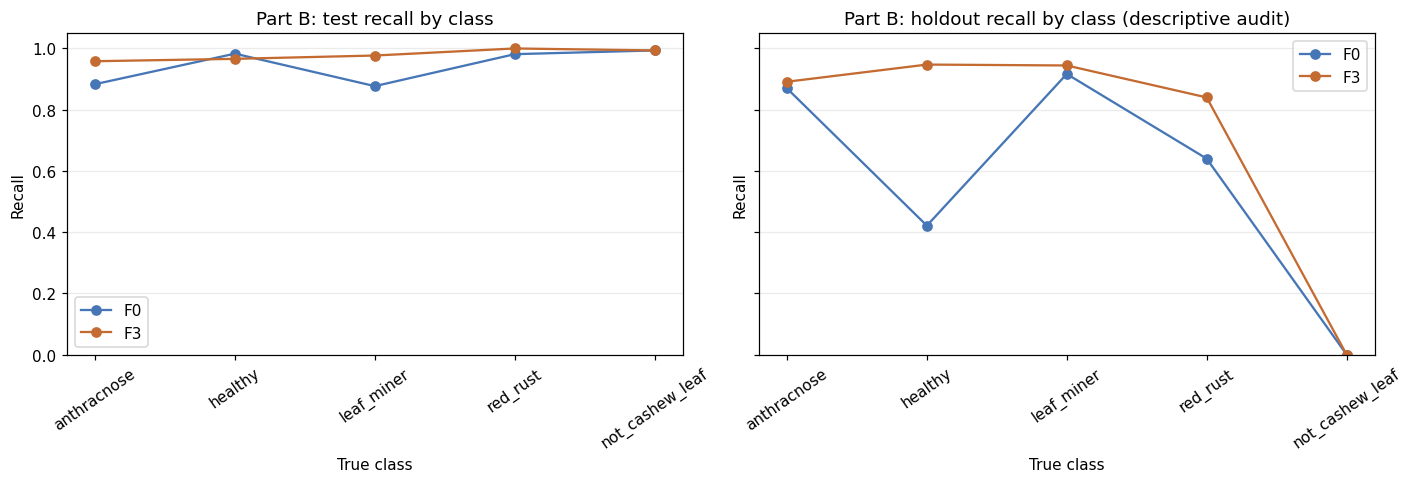

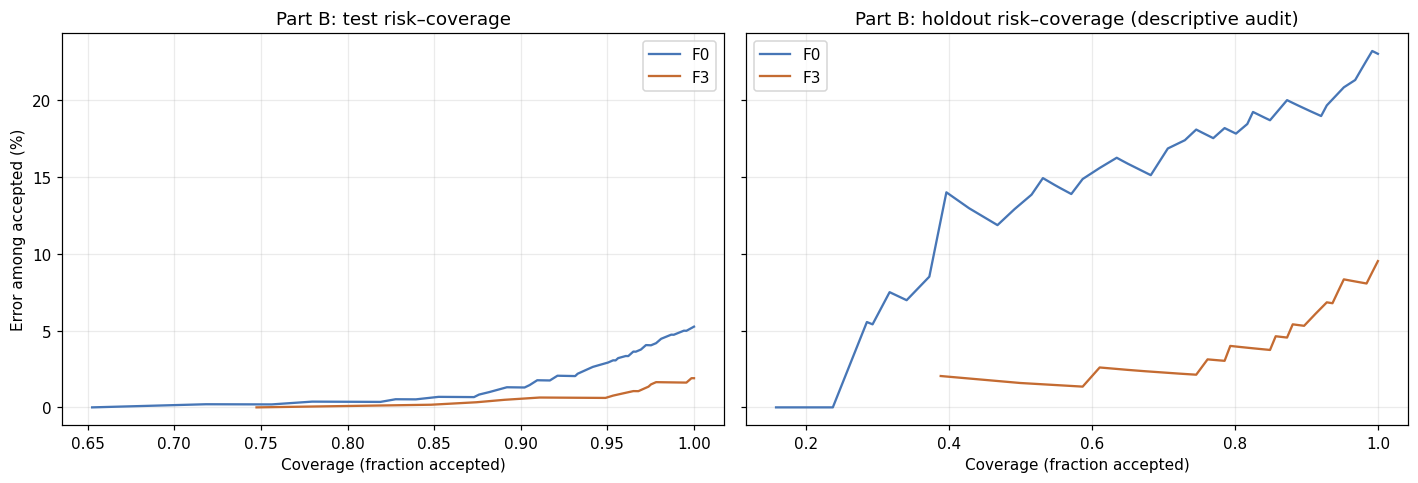

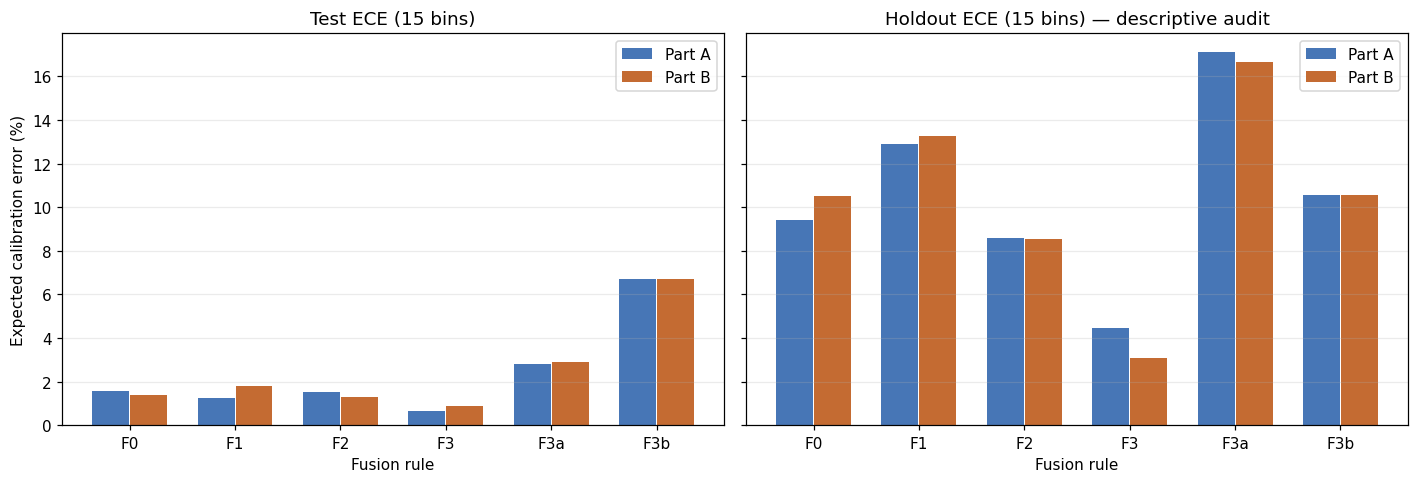

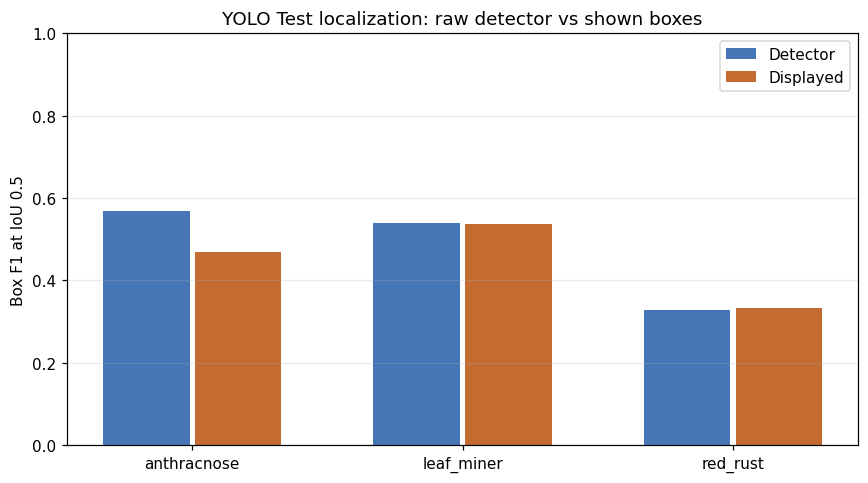

Saved 7 validation figures to /content/training_results/current_dataset/EXP-RESNET50-YOLO-PIPELINE-033/aggregate/figures
accuracy_wilson.png
paired_bootstrap_vs_f0.png
confusion_selected_rule.png
recall_by_class.png
risk_coverage.png
calibration_ece15.png
localization_f1.png


In [24]:
# EXP-033 — render validation figures from existing aggregate CSVs.
# Run after the evaluation/localization cell, before the ANALYSIS snapshot upload cell.
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if "OUT_DIR" in globals():
    figure_root = Path(OUT_DIR)
else:
    candidates = [p for p in Path("/content/training_results/current_dataset").glob(
        "EXP-DENSENET121-YOLO-PIPELINE-032*") if p.is_dir()]
    if len(candidates) != 1:
        raise RuntimeError(f"Set OUT_DIR to the intended EXP-033 result folder: {candidates}")
    figure_root = candidates[0]
aggregate = figure_root / "aggregate"
if not aggregate.is_dir():
    raise FileNotFoundError(f"No aggregate results in {figure_root}")
figures = aggregate / "figures"
figures.mkdir(exist_ok=True)
classes = ["anthracnose", "healthy", "leaf_miner", "red_rust", "not_cashew_leaf"]
rules = ["F0", "F1", "F2", "F3", "F3a", "F3b"]

def read_table(name):
    path = aggregate / name
    return pd.read_csv(path) if path.is_file() else pd.DataFrame()

results = pd.concat([read_table("fusion_results_partA.csv"),
                     read_table("fusion_results_partB.csv")], ignore_index=True)
if results.empty:
    raise RuntimeError("No fusion results yet; run Part A or B first")
boot = read_table("paired_bootstrap.csv")
risk = read_table("risk_coverage.csv")
localization = read_table("localization_test.csv")
part = "B" if "B" in set(results.part) else "A"
if "SELECTED_DEFAULT" in globals() and part == "B":
    selected = SELECTED_DEFAULT
elif (aggregate / "exp033_summary.json").is_file() and part == "B":
    selected = json.loads((aggregate / "exp033_summary.json").read_text(
        encoding="utf-8")).get("selected_default_rule") or "F0"
else:
    selected = "F0"
if selected not in rules:
    raise RuntimeError(f"Unknown selected rule: {selected}")
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 170, "font.size": 10})
made = []

def save(fig, name):
    fig.tight_layout()
    destination = figures / name
    fig.savefig(destination, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    made.append(destination)

# Wilson intervals describe each accuracy separately; they are not the paired rule comparison.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, split in zip(axes, ("test", "holdout")):
    sub = results[results.split == split]
    for offset, current_part, color in ((-0.11, "A", "#4776b6"),
                                        (0.11, "B", "#c46b32")):
        group = sub[sub.part == current_part].set_index("rule")
        if group.empty:
            continue
        present = [r for r in rules if r in group.index]
        vals = group.loc[present]
        if not {"accuracy", "wilson_low", "wilson_high"}.issubset(vals.columns):
            continue
        x = np.array([rules.index(r) for r in present], dtype=float) + offset
        y = vals.accuracy.to_numpy(dtype=float) * 100
        err = np.vstack((y - vals.wilson_low.to_numpy(dtype=float) * 100,
                         vals.wilson_high.to_numpy(dtype=float) * 100 - y))
        ax.errorbar(x, y, yerr=err, fmt="o", capsize=3, color=color,
                    label=f"Part {current_part}")
    ax.set(title=f"{split.title()} accuracy (Wilson 95% CI)", xlabel="Fusion rule",
           xticks=range(len(rules)), xticklabels=rules)
    ax.grid(axis="y", alpha=.25)
    if split == "holdout":
        ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                transform=ax.transAxes, fontsize=8)
    ax.legend(loc="best")
axes[0].set_ylabel("Accuracy (%)")
save(fig, "accuracy_wilson.png")

if not boot.empty:
    sub = boot[boot.split.isin(["test", "holdout"])].copy()
    fig, axes = plt.subplots(1, 2, figsize=(13, 6), sharex=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = sub[sub.split == split]
        labels = [f"{p} / {r}" for p in ("A", "B") for r in rules[1:]
                  if ((view.part == p) & (view.rule == r)).any()]
        for y, label in enumerate(labels):
            p, r = label.split(" / ")
            row = view[(view.part == p) & (view.rule == r)].iloc[0]
            lo, mid, hi = [100 * float(row[k]) for k in
                           ("bootstrap_low", "delta_accuracy", "bootstrap_high")]
            ax.plot([lo, hi], [y, y], color="#4776b6" if p == "A" else "#c46b32", lw=2)
            ax.plot(mid, y, "o", color="#4776b6" if p == "A" else "#c46b32")
        ax.axvline(0, color="black", lw=1, ls="--")
        ax.set(yticks=range(len(labels)), yticklabels=labels,
               title=f"{split.title()}: paired bootstrap, 10,000 resamples",
               xlabel="Accuracy difference vs F0 (percentage points)")
        ax.grid(axis="x", alpha=.25)
        if split == "holdout":
            ax.text(.02, .02, "Descriptive audit; not a blind benchmark",
                    transform=ax.transAxes, fontsize=8)
    axes[1].invert_yaxis()
    save(fig, "paired_bootstrap_vs_f0.png")

def confusion(part_name, split, rule):
    path = aggregate / f"confusion_{part_name}_{split}_{rule}.csv"
    return pd.read_csv(path, index_col=0) if path.is_file() else None

matrix_test = confusion(part, "test", selected)
matrix_hold = confusion(part, "holdout", selected)
if matrix_test is not None or matrix_hold is not None:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
    for ax, split, matrix in zip(axes, ("test", "holdout"),
                                 (matrix_test, matrix_hold)):
        if matrix is None:
            ax.set_axis_off()
            continue
        values = matrix.to_numpy(dtype=int)
        ax.imshow(values, cmap="Blues")
        for i in range(values.shape[0]):
            for j in range(values.shape[1]):
                ax.text(j, i, str(values[i, j]), ha="center", va="center",
                        color="white" if values[i, j] > values.max() / 2 else "black")
        ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns,
               yticks=range(len(matrix.index)), yticklabels=matrix.index,
               xlabel="Predicted", ylabel="True",
               title=f"Part {part} {selected} — {split}" +
                     (" (descriptive audit)" if split == "holdout" else ""))
        ax.tick_params(axis="x", labelrotation=45)
    save(fig, "confusion_selected_rule.png")

recall_cols = [f"recall_{name}" for name in classes]
if set(recall_cols).issubset(results.columns):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        subset = results[(results.part == part) & (results.split == split)]
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            row = subset[subset.rule == rule]
            if row.empty:
                continue
            ax.plot(classes, row.iloc[0][recall_cols].to_numpy(dtype=float), "o-",
                    label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} recall by class" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               ylim=(0, 1.05), ylabel="Recall", xlabel="True class")
        ax.tick_params(axis="x", labelrotation=35)
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    save(fig, "recall_by_class.png")

if not risk.empty:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        for rule, color in (("F0", "#4776b6"), (selected, "#c46b32")):
            view = risk[(risk.part == part) & (risk.split == split) &
                        (risk.rule == rule)].dropna(subset=["coverage", "risk"])
            if not view.empty:
                ax.plot(view.coverage, 100 * view.risk, label=rule, color=color)
            if rule == selected:
                break
        ax.set(title=f"Part {part}: {split} risk–coverage" +
                     (" (descriptive audit)" if split == "holdout" else ""),
               xlabel="Coverage (fraction accepted)")
        ax.grid(alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Error among accepted (%)")
    save(fig, "risk_coverage.png")

if "ece15" in results.columns:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
    for ax, split in zip(axes, ("test", "holdout")):
        view = results[results.split == split]
        x = np.arange(len(rules))
        for offset, current_part, color in ((-.18, "A", "#4776b6"),
                                            (.18, "B", "#c46b32")):
            group = view[view.part == current_part].set_index("rule")
            vals = [100 * float(group.loc[r, "ece15"]) if r in group.index
                    else np.nan for r in rules]
            if np.isfinite(vals).any():
                ax.bar(x + offset, vals, width=.35, label=f"Part {current_part}",
                       color=color)
        ax.set(xticks=x, xticklabels=rules, title=f"{split.title()} ECE (15 bins)" +
               (" — descriptive audit" if split == "holdout" else ""),
               xlabel="Fusion rule")
        ax.grid(axis="y", alpha=.25)
        ax.legend()
    axes[0].set_ylabel("Expected calibration error (%)")
    save(fig, "calibration_ece15.png")

if not localization.empty:
    view = localization[localization.subset == "all"].copy()
    if "mode" not in view.columns:
        view["mode"] = "detector_only"
    fig, ax = plt.subplots(figsize=(8, 4.5))
    x = np.arange(3)
    for offset, mode, label, color in ((-.17, "detector_only", "Detector", "#4776b6"),
                                       (.17, "fused_display", "Displayed", "#c46b32")):
        vals = []
        for cls in ("anthracnose", "leaf_miner", "red_rust"):
            row = view[(view["class"] == cls) & (view["mode"] == mode)]
            vals.append(float(row.iloc[0].f1_50) if not row.empty else np.nan)
        if np.isfinite(vals).any():
            ax.bar(x + offset, vals, width=.32, label=label, color=color)
    ax.set(xticks=x, xticklabels=["anthracnose", "leaf_miner", "red_rust"],
           ylim=(0, 1), ylabel="Box F1 at IoU 0.5",
           title="YOLO Test localization: raw detector vs shown boxes")
    ax.legend()
    ax.grid(axis="y", alpha=.25)
    save(fig, "localization_f1.png")

note = ("# EXP-033 validation figures\n\n"
        "Generated from aggregate CSVs without fitting or selecting any parameters.\n\n"
        "Wilson intervals describe single-rule accuracy. The paired bootstrap figure "
        "shows the 95% interval of each rule's difference from F0. Holdout figures "
        "are descriptive audits, not blind benchmarks. Localization uses labeled "
        "YOLO Test only; Holdout has no box ground truth. The risk–coverage curves "
        "sweep thresholds for illustration and do not retune the frozen abstention "
        "threshold. The ECE bar chart summarizes calibration error; a reliability diagram "
        "requires per-image calibrated probabilities, which the aggregate tables "
        "do not retain.\n")
(figures / "README.md").write_text(note, encoding="utf-8")
print("Saved", len(made), "validation figures to", figures)
for path in made:
    print(path.name)


In [25]:
# Report, optional blind hook, integrity manifest, immutable ZIP upload.
def metric(part,split,rule):
    return next(r for r in ALL_RESULTS if r["part"]==part and r["split"]==split and r["rule"]==rule)

dense_reference = {}
if DENSENET032_ANALYSIS_OVERRIDE:
    reference_path = Path(DENSENET032_ANALYSIS_OVERRIDE)
    if not reference_path.is_file():
        raise FileNotFoundError(reference_path)
    with zipfile.ZipFile(reference_path) as reference:
        if reference.testzip() is not None:
            raise RuntimeError("Corrupt DenseNet 032 reference ZIP")
        for part in ("A", "B"):
            suffix = f"/aggregate/fusion_results_part{part}.csv"
            matches = [n for n in reference.namelist() if n.endswith(suffix)]
            if len(matches) != 1:
                raise RuntimeError(f"DenseNet 032 reference table missing: {suffix}")
            dense_reference[part] = pd.read_csv(io.BytesIO(reference.read(matches[0])))
comparison = []
for part in ("A", "B"):
    for split in ("validation_clean", "test", "holdout"):
        if not any(r["part"] == part and r["split"] == split for r in ALL_RESULTS):
            continue
        f0 = metric(part, split, "F0")["accuracy"]
        for rule in RULES:
            row = metric(part, split, rule)
            reference = dense_reference.get(part)
            dense = reference[(reference["split"] == split) & (reference["rule"] == rule)] if reference is not None else None
            dense_score = float(dense.iloc[0]["accuracy"]) if dense is not None and len(dense) == 1 else np.nan
            comparison.append({"part": part, "split": split, "rule": rule,
                "resnet50_yolo_accuracy": row["accuracy"], "resnet50_f0_accuracy": f0,
                "resnet50_delta_vs_f0": row["accuracy"] - f0,
                "densenet121_yolo_accuracy": dense_score,
                "densenet_reference_status": "provided" if np.isfinite(dense_score) else "unavailable"})
pd.DataFrame(comparison).to_csv(AGGREGATE / "classifier_comparison.csv", index=False)

summary={"experiment_id":EXPERIMENT_ID,"dry_run":DRY_RUN,
         "selected_default_rule":SELECTED_DEFAULT if RUN_PART_B else None,
         "input_pins":{"split13_file_id":DATASET_ARCHIVE_FILE_ID,
                       "split13_sha256":DATASET_ARCHIVE_SHA256,
                       "holdout09_file_id":REAL_HOLDOUT_ARCHIVE_FILE_ID,
                       "yolo_dataset_file_id":YOLO_DATASET_FILE_ID,
                       "detector_weights_sha256":DETECTOR_WEIGHTS_SHA256},
         "leakage":AUDIT,"fusion_results":ALL_RESULTS,
         "paired_bootstrap":ALL_BOOTSTRAP,"localization":LOCALIZATION,
         "box_conf":float(BOX_CONF),
         "known_holdout_issue":"real_healthy_40.jpg and real_healthy_42.jpg are byte-identical to old Split12 Train anthracnose images; GT stays healthy; n=124 secondary metric",
         "partA_disclosure":"ResNet50 032 was chosen over 031 by the user for Stage 2 stability after Test/Holdout had been viewed. 031 has lower val_loss. F2 is post hoc; Holdout is descriptive.",
         "holdout_status":"descriptive audit, not a blind benchmark",
         "calibration_limit":"Temperature fitted on clean Validation; learned stacker temperature uses in-sample predictions and may be optimistic",
         "stubs_used":["synthetic image tree","stub detector","random-init ResNet50","2 seeds","1 epoch per stage"] if DRY_RUN else []}
write_json(AGGREGATE/"exp033_summary.json",summary)

lines=["# EXP-033 result", "", "See classifier_comparison.csv for ResNet50 versus F0 and DenseNet121; DenseNet cells are NA unless its result ZIP is supplied.", "",f"Default rule: **{summary['selected_default_rule']}**" if RUN_PART_B else
       "Part A only; no deployable default rule selected.","",
       "Holdout 09: descriptive audit, not a blind benchmark. It has been inspected previously.",
       "Two known duplicate Holdout images retain their healthy labels; see n=124 metric.",
       "ResNet50 032 was selected over 031 for Stage 2 stability after Test/Holdout inspection; 031 has lower val_loss. F2 is post hoc.",
       "Confidence uses Validation-fitted temperature scaling. In-sample stacker calibration may be optimistic.",
       "YOLO best.pt was chosen on YOLO Val; BOX_CONF chosen there is slightly optimistic. YOLO Test is the clean localization split.",""]
for part in ("A","B"):
    if not any(r["part"]==part for r in ALL_RESULTS): continue
    lines.extend([f"## Part {part}","","| Rule | Clean Val | Test | Holdout | Holdout n=124 | Gap |",
                  "|---|---:|---:|---:|---:|---:|"])
    for rule in RULES:
        val=metric(part,"validation_clean",rule)["accuracy"]
        test=metric(part,"test",rule)["accuracy"]
        hold=metric(part,"holdout",rule)["accuracy"]
        hold124=metric(part,"holdout_n124",rule)["accuracy"]
        lines.append(f"| {rule} | {val:.4f} | {test:.4f} | {hold:.4f} | {hold124:.4f} | {test-hold:.4f} |")
    lines.append("")
lines.extend(["## Localization","","See `localization_test.csv` for per-class IoU 0.5 precision/recall/F1, mAP50, mAP50-95, `real_` and near-duplicate exclusions.",
              f"BOX_CONF={BOX_CONF:.3f}; detector boxes are filtered by final class, class-wise NMS 0.5, and capped at 20 for display.",
              "Holdout panels are qualitative only: Holdout has no box ground truth.","",
              "## Decision and limits","",
              "The predeclared Part B rule decides the deployable default. F2 is explicitly post hoc.",
              "Abstained images mean expert review and do not count as correct.",
              "The 126-image Holdout has a wide confidence interval; a gap below 10 points alone does not establish success.",
              "A future blind real-field set is needed for a confirmatory claim.",
              "Completed runs export both ANALYSIS (tables/predictions) and FULL (models + tables) ZIPs. "
              "Per-seed ZIPs are disconnect recovery checkpoints."])
if DRY_RUN: lines += ["","**Synthetic dry run only. No real EXP-033 scores were produced.**"]
(AGGREGATE/"README.md").write_text("\n".join(lines)+"\n",encoding="utf-8")

if USE_EXTRA_BLIND_SET:
    if not RUN_PART_B: raise RuntimeError("Blind hook requires the exported pipeline")
    service=drive_client()
    blind_root=STAGE_ROOT/"blind10"
    blind_root.mkdir(parents=True,exist_ok=True)
    # Folder ID is required only for opt-in; download its class subfolders.
    def copy_folder(folder_id,target):
        from googleapiclient.http import MediaIoBaseDownload
        query=f"'{folder_id}' in parents and trashed = false"
        page=None
        while True:
            response=service.files().list(q=query,fields="nextPageToken,files(id,name,mimeType,size)",
                pageToken=page,pageSize=1000,supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
            for item in response["files"]:
                dest=target/item["name"]
                assert dest.resolve().is_relative_to(blind_root.resolve())
                if item["mimeType"]=="application/vnd.google-apps.folder":
                    dest.mkdir(exist_ok=True);copy_folder(item["id"],dest)
                else:
                    request=service.files().get_media(fileId=item["id"],supportsAllDrives=True)
                    with dest.open("wb") as stream:
                        download=MediaIoBaseDownload(stream,request,chunksize=8<<20);done=False
                        while not done: _,done=download.next_chunk(num_retries=3)
                    assert dest.stat().st_size==int(item["size"])
            page=response.get("nextPageToken")
            if not page: break
    copy_folder(EXTRA_BLIND_DRIVE_FOLDER_ID,blind_root)
    blind_paths=image_files(blind_root)
    blind_rows=[{"key":p.relative_to(blind_root).as_posix(),"true":p.parent.name,
                 "pred":pipeline.predict(p)["label"]} for p in blind_paths]
    accuracy=np.mean([r["true"]==r["pred"] for r in blind_rows]) if blind_rows else np.nan
    (AGGREGATE/"blind10_report.md").write_text(
        f"# Optional blind10 (frozen pipeline, after Holdout)\n\nN={len(blind_rows)}, accuracy={accuracy:.4f}. No parameter selection.\n",
        encoding="utf-8")

# Per-seed Drive ZIPs are recovery checkpoints. Final archives follow all gates.
# Required V2 artifact audit before archiving.
required = [AGGREGATE / "tau_selection.json", AGGREGATE / "leakage_audit.json",
            AGGREGATE / "pipeline_latency_batch1.json", AGGREGATE / "fusion_results_partA.csv",
            AGGREGATE / "analysis_manifest.json"]
if RUN_PART_B:
    required += [AGGREGATE / "fusion_results_partB.csv", OUT_DIR / "pipeline_bundle" / "cashew_pipeline.py"]
write_json(AGGREGATE / "audit_required_artifacts.json", {
    "experiment_id": EXPERIMENT_ID,
    "checks": [{"path": p.relative_to(OUT_DIR).as_posix(), "exists": p.is_file()}
               for p in required if p.name != "analysis_manifest.json"],
    "status": "PASS" if all(p.is_file() for p in required if p.name != "analysis_manifest.json") else "FAIL"})
if any(not p.is_file() for p in required if p.name != "analysis_manifest.json"):
    raise RuntimeError("Required V2 artifact missing")

analysis_files=sorted(path for path in OUT_DIR.rglob("*") if path.is_file() and
    (path.is_relative_to(AGGREGATE) or path.name=="seed_summary.json" or
     path.name.endswith("_predictions.csv")))
if not analysis_files:
    raise RuntimeError("No analysis files to archive")
analysis_manifest=[{"path":path.relative_to(OUT_DIR).as_posix(),
                    "bytes":path.stat().st_size,"sha256":file_sha256(path)}
                   for path in analysis_files]
write_json(AGGREGATE/"analysis_manifest.json",analysis_manifest)

manifest=[]
for path in sorted(OUT_DIR.rglob("*")):
    if path.is_file() and path.name!="artifact_sha256.csv":
        manifest.append({"path":path.relative_to(OUT_DIR).as_posix(),"bytes":path.stat().st_size,
                         "sha256":file_sha256(path)})
pd.DataFrame(manifest).to_csv(AGGREGATE/"artifact_sha256.csv",index=False)

analysis_zip=OUT_DIR.parent/f"{OUT_DIR.name}_ANALYSIS.zip"
full_zip=OUT_DIR.parent/f"{OUT_DIR.name}_FULL.zip"
with zipfile.ZipFile(analysis_zip,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
    for item in sorted(OUT_DIR.rglob("*")):
        if item.is_file() and (item.is_relative_to(AGGREGATE) or item.name=="seed_summary.json" or
                               item.name.endswith("_predictions.csv")):
            archive.write(item,f"{OUT_DIR.name}/{item.relative_to(OUT_DIR).as_posix()}")
with zipfile.ZipFile(full_zip,"w",zipfile.ZIP_DEFLATED,compresslevel=6,allowZip64=True) as archive:
    for item in sorted(OUT_DIR.rglob("*")):
        if item.is_file():
            archive.write(item,f"{OUT_DIR.name}/{item.relative_to(OUT_DIR).as_posix()}")
for archive_path in (analysis_zip,full_zip):
    with zipfile.ZipFile(archive_path) as archive:
        if archive.testzip() is not None:
            raise RuntimeError(f"Corrupt result archive: {archive_path}")
    print(archive_path.name,"bytes",archive_path.stat().st_size,
          "SHA256",file_sha256(archive_path))

if UPLOAD_RESULT_ZIPS_TO_DRIVE:
    if RUN_PART_B:
        service=drive_client()
        upload_archive=lambda archive_path: upload_immutable(service,archive_path)
    else:
        import google.auth
        from googleapiclient.discovery import build
        from googleapiclient.http import MediaFileUpload
        if Path("/content").is_dir():
            from google.colab import auth
            auth.authenticate_user()
        credentials,_=google.auth.default(scopes=["https://www.googleapis.com/auth/drive"])
        service=build("drive","v3",credentials=credentials,cache_discovery=False)
        def upload_archive(archive_path):
            query=(f"name = '{archive_path.name}' and "
                   f"'{DRIVE_TARGET_FOLDER_ID}' in parents and trashed = false")
            found=service.files().list(q=query,fields="nextPageToken,files(id,name,size,md5Checksum)",
                supportsAllDrives=True,includeItemsFromAllDrives=True).execute()
            matches=found.get("files") or []
            if found.get("nextPageToken") or len(matches)>1:
                raise RuntimeError(f"Ambiguous Drive archive: {archive_path.name}")
            digest=file_md5(archive_path)
            if matches:
                if int(matches[0].get("size",-1))!=archive_path.stat().st_size or \
                        matches[0].get("md5Checksum")!=digest:
                    raise RuntimeError(f"Refusing to overwrite Drive archive: {archive_path.name}")
                return matches[0]["id"]
            media=MediaFileUpload(str(archive_path),mimetype="application/zip",resumable=True)
            request=service.files().create(body={"name":archive_path.name,
                "parents":[DRIVE_TARGET_FOLDER_ID]},media_body=media,
                fields="id",supportsAllDrives=True)
            uploaded=None
            while uploaded is None:
                _,uploaded=request.next_chunk(num_retries=3)
            return uploaded["id"]
    for archive_path in (analysis_zip,full_zip):
        file_id=upload_archive(archive_path)
        remote=service.files().get(fileId=file_id,
            fields="id,name,size,md5Checksum,parents",supportsAllDrives=True).execute()
        digest=file_md5(archive_path)
        if (remote["name"]!=archive_path.name or
                int(remote["size"])!=archive_path.stat().st_size or
                remote.get("md5Checksum")!=digest or
                DRIVE_TARGET_FOLDER_ID not in remote.get("parents",[])):
            raise RuntimeError(f"Drive archive verification failed: {archive_path.name}")
        print("Drive verified",archive_path.name,file_id,remote["size"])


EXP-RESNET50-YOLO-PIPELINE-033_ANALYSIS.zip bytes 30839801 SHA256 1cd29a14593b3748f6e5b5716f85fdc0e1e5280e77f40365f74da3bf2ff8dad6
EXP-RESNET50-YOLO-PIPELINE-033_FULL.zip bytes 2299026323 SHA256 cc9ccd14a18023f39a09352305bb878fe6f5a3c9131ae179800c2d2af2ad1580


Verified upload EXP-RESNET50-YOLO-PIPELINE-033_ANALYSIS.zip 1f-E7GJIgk-b7eO9opjodS1E5MrMewRtI
Drive verified EXP-RESNET50-YOLO-PIPELINE-033_ANALYSIS.zip 1f-E7GJIgk-b7eO9opjodS1E5MrMewRtI 30839801
Verified upload EXP-RESNET50-YOLO-PIPELINE-033_FULL.zip 1T5kByJrkh-UAFTDrYfDff4AQfosy39LU
Drive verified EXP-RESNET50-YOLO-PIPELINE-033_FULL.zip 1T5kByJrkh-UAFTDrYfDff4AQfosy39LU 2299026323
